# Zenteno S · ponderación de biomasa y temperatura causal

Se recalibra el modelo de cuatro estados del notebook 17 con azúcar total S, biomasa X, YAN N y etanol E. Se comparan σX de 0,50 y 0,25 g/L usando la misma temperatura causal, los mismos lotes de calibración LAB004–009 y los mismos holdouts químicos LAB016–024 del notebook 24. Se usan todas las muestras válidas de biomasa posteriores a la inicial. La tercera curva usa los parámetros publicados del modelo S del notebook 17 con la misma entrada térmica causal.

Se ajustan μ0, βS0, Ks0, Yxn y Yes. Se fijan Kie0, Kn0, Kd0, m0 e Yxs según el notebook 17. Para el gas se usa la solubilidad variable y la pareja de coeficientes del modelo S publicada en el 17.

## Solubilidad variable y predicción de gas
Se usan los coeficientes de transferencia y ganancia calibrados en el notebook 17. Cambia la trayectoria química que alimenta el cálculo de gas.

The empirical wine correlation reproduced as Eq. 1 in Liger-Belair et al. (2023), attributed there to Lonvaud-Funel and Matsumoto, is
\[
k_H=3.295\exp[(7\times10^{-5}a-0.02905)T-0.0179a-0.00111S],\qquad C_{sat}=k_Hp_{CO_2}.
\]
T is in °C, a is ethanol % vol, S is total sugar in g/L, kH is in g/(L bar). Ethanol conversion uses a=E/7.8924, with pure ethanol density 789.24 g/L at 20°C as a reference conversion, not an evolving mixture density. Measured temperature and model-predicted ethanol/sugar vary throughout each batch. Coefficients are fixed; pCO2=1 bar is an explicit assumption, not a pressure measurement. Application to fermenting must is an extrapolation requiring validation, particularly at high sugar. Source: https://doi.org/10.1021/acsomega.3c01812 . The historical provisional correlation is not used.

The transfer law below is our adaptation, not an equation attributed to that paper:
\[
q_{eff}=Aq_{prod},\quad r_{abs}=\min(q_{eff},k_La\max(C_{sat}-C_d,0)),\quad
r_{des}=k_La\max(C_d-C_{sat},0),\quad
\dot C_d=r_{abs}-r_{des},\quad q_{gas}=q_{eff}-\dot C_d,\quad q_{pred}=gq_{gas}.
\]
This retains the previous absorption-limited reservoir and adds release above equilibrium. Cd is not clipped to changing saturation: supersaturation can persist and relax. Cd(0)=0 is retained. The same effective source activation is retained, so conservation applies to that source, not to unattenuated stoichiometric production. kLa is an effective coefficient in this adapted law, not an independently measured physical transfer coefficient.

Exact piecewise integration for interval-constant midpoint saturation and interval-mean production preserves positivity and concentration balance. Finite-volume mass checks include homogeneous withdrawals; gain is outside the balance.
Los intervalos de gas se dividen en cada actualización del sensor. La temperatura disponible al inicio del intervalo se mantiene al calcular la producción y la solubilidad dentro de él.

In [1]:
from pathlib import Path
import re
from dataclasses import replace
import sys,json,hashlib,math,time
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/wine_fermentation').is_dir())
try:
    from numba import njit
except ImportError:
    def njit(function):
        return function
sys.path.insert(0,str(ROOT/'src'));sys.dont_write_bytecode=True
from wine_fermentation import model as kin
from wine_fermentation.data import natural_batches
from wine_fermentation.models.historical.calibration import load
from wine_fermentation.comparison import observations,chemical_observations,CHEMICAL_COLUMNS
protected=[p for folder in ['src','configs','data/compatibility/chemistry','data/cleaned/natural/lab004_009'] for p in (ROOT/folder).rglob('*') if p.is_file() and '__pycache__' not in str(p) and '_variable_solubility.' not in p.name]
protected += [ROOT/'notebooks/16_zenteno_recalibration_legacy_treatment_variable_solubility.source.ipynb']
hashes={p:hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
data,training,_=natural_batches(ROOT)
# Correcciones de recuento inicial indicadas por el usuario; originales conservados.
INITIAL_VIABLE_MCELLS_ML={'LAB004':10.75,'LAB005':11.25}
initial_biomass_audit=[];corrected_training=[]
for batch in training:
 if batch.batch in INITIAL_VIABLE_MCELLS_ML:
  count=INITIAL_VIABLE_MCELLS_ML[batch.batch];x0=count*.03
  ids=np.flatnonzero(np.isclose(batch.time,0.));assert len(ids)==1
  obs0={k:v.copy() for k,v in batch.observations.items()};obs0['X'][ids[0]]=x0
  initial_biomass_audit.append(dict(LAB=batch.batch,original_g_L=batch.initials['X'],viables_millones_mL=count,corregido_g_L=x0))
  batch=replace(batch,initials={**batch.initials,'X':x0},observations=obs0)
  mask=data.batch.eq(batch.batch)&np.isclose(data.time_h,0.)
  assert mask.sum()==1
  data.loc[mask,'X_viable_kg_m3']=x0;data.loc[mask,'X_viable_mcells_ml']=count
  assert batch.initials['X']==batch.observations['X'][ids[0]]
 corrected_training.append(batch)
training=corrected_training
assert len(initial_biomass_audit)==2
display(pd.DataFrame(initial_biomass_audit))

gf_seed=kin.normalize_parameters(json.loads((ROOT/'configs/theta/theta_full.json').read_text()))
published_theta={'mu0': 0.09085058816701197, 'betaS0': 0.8189664538991809, 'Ks0': 23.046564567082594, 'Kie0': 96.26516563486751, 'Yxn': 6.497331613020979, 'Yes': 0.4893180893478443}
fixed=dict(Kie0=published_theta['Kie0'],Kn0=.008257860224319971,Kd0=.00044,
           m0=gf_seed['m0'],Yxs=1/(1/gf_seed['Yxg']+1/gf_seed['Yxf']))
published_theta.update(fixed)
start={**fixed,'mu0':.09403147367985473,'betaS0':.42243676903335664+.6236552480900203,
       'Ks0':10.,'Yxn':6.456225797038313,'Yes':.49}
bounds=dict(mu0=(.05,1.),betaS0=(.1,20.),Ks0=(.1,200.),Yxn=(1.,100.),Yes=(.1,.5114))
names=list(bounds)
lo,hi=np.array(list(bounds.values())).T
STATES=('X','N','S','E')
S_PARAMETERS=(*names,*fixed)
display(pd.Series(fixed,name='Fijos del modelo S del notebook 17'))
display(pd.DataFrame([dict(parámetro=k,inicio=start[k],mínimo=lo[i],máximo=hi[i]) for i,k in enumerate(names)]))


,LAB,original_g_L,viables_millones_mL,corregido_g_L
0,LAB004,0.3939,10.75,0.3225
1,LAB005,0.4932,11.25,0.3375


Kie0    96.265166
Kn0      0.008258
Kd0      0.000440
m0       0.018339
Yxs      0.516507
Name: Fijos del modelo S del notebook 17, dtype: float64

,parámetro,inicio,mínimo,máximo
0,mu0,0.094031,0.05,1.0000
1,betaS0,1.046092,0.10,20.0000
2,Ks0,10.000000,0.10,200.0000
3,Yxn,6.456226,1.00,100.0000
4,Yes,0.490000,0.10,0.5114


## Observaciones y ponderación

Se conservan las muestras válidas de biomasa a todas las horas. La biomasa inicial se usa como condición inicial. El tratamiento de YAN sigue el notebook 16, incluido el criterio manual de agotamiento a las 122 h para LAB006.

La temperatura sigue la regla del EKF online. Se calcula la mediana de cada minuto completado desde el reloj del lote y se mantiene hasta el cierre del siguiente minuto con lecturas. Se usa el mismo valor en el crecimiento, la fermentación, la mortalidad y la solubilidad. Ante un hueco se mantiene la última mediana disponible. Si al inicio todavía no hay un minuto completado, se conserva el estado inicial hasta disponer de temperatura. La auditoría muestra el tiempo de espera y los mayores intervalos entre actualizaciones.

En LAB004–009 se forma S sumando G y F de la misma muestra. Su escala de error combina en cuadratura las escalas de ambos ensayos, como en el notebook 17.

In [2]:
treated=[];audit=[];rules=[]
for b in training:
 obs={k:v.copy() for k,v in b.observations.items()};old=obs['N'].copy()
 obs['N'][np.isfinite(old)&(old<=.020)]=0
 if b.batch=='LAB006':
  ids=np.flatnonzero(np.isclose(b.time,122)&np.isfinite(old));assert len(ids)==1 and np.isclose(old[ids[0]],.027)
  obs['N'][ids]=0;depletion=122.
 else:
  last=max(t for t,d in b.pulses['N']);ids=np.flatnonzero((b.time>=last)&np.isfinite(obs['N'])&(obs['N']==0));assert len(ids)
  depletion=float(b.time[ids[0]])
 obs['N'][b.time>depletion+12]=np.nan
 for i in np.flatnonzero(np.isfinite(old)):
  audit.append(dict(LAB=b.batch,t_h=b.time[i],original_mg=old[i]*1000,usado_mg=obs['N'][i]*1000,estado='Inicial' if b.time[i]==0 else ('Excluido' if not np.isfinite(obs['N'][i]) else ('Transformado' if old[i]!=obs['N'][i] else 'Usado'))))
 assert all(np.array_equal(obs[k],b.observations[k],equal_nan=True) for k in obs if k!='N')
 treated.append(replace(b,observations=obs))
 rules.append(dict(LAB=b.batch,agotamiento_h=depletion,corte_YAN_h=depletion+12,N0_mg=b.initials['N']*1000,pulsos=b.pulses['N'],**{k:int(np.count_nonzero(np.isfinite(obs[k])&(b.time>0))) for k in obs}))
audit=pd.DataFrame(audit);display(pd.DataFrame(rules));display(audit)
def sigma(state,y,sigma_x):return np.full_like(y,sigma_x) if state=='X' else kin.sigma_for_state(state,y)
thermal_profiles={}

def register_temperature(lab, raw):
    sensor=raw[['t_h','T']].apply(pd.to_numeric,errors='coerce').dropna()
    sensor=sensor.loc[np.isfinite(sensor).all(axis=1)].sort_values('t_h')
    minute=np.floor(sensor.t_h.to_numpy()*60).astype(int)
    medians=sensor.groupby(minute)['T'].median()
    if medians.empty:
        raise ValueError(f'{lab}: registro de temperatura vacío')
    available=(medians.index.to_numpy()+1)/60
    assert np.all(np.diff(available)>0)
    # Una lectura contribuye únicamente después del cierre de su minuto.
    assert np.all(sensor.t_h.to_numpy()<(minute+1)/60+1e-12)
    thermal_profiles[lab]=(available,medians.to_numpy(float))


def causal_temperature(batch,time):
    available,values=thermal_profiles[batch.batch]
    index=np.searchsorted(available,time+1e-12,side='right')-1
    if np.any(index<0):
        raise ValueError(f'{batch.batch}: temperatura aún no disponible')
    return values[index]


def propagation_start(batch):
    return max(float(batch.time[0]),float(thermal_profiles[batch.batch][0][0]))


clocks=pd.read_csv(ROOT/'data/compatibility/chemistry/clocks.csv').set_index('batch').t0
temp_paths=list((ROOT/'data/original/natural/process_logs').rglob('*.csv'))
for batch in treated:
    files=sorted(path for path in temp_paths if path.name.lower().startswith('temp') and
                 re.search(rf'lab0*{int(batch.batch[3:])}(?:\D|$)',path.name,re.I))
    raw=pd.concat([pd.read_csv(path,usecols=['timestamp','T']) for path in files])
    raw['timestamp']=pd.to_datetime(raw.timestamp,errors='coerce')
    raw['T']=pd.to_numeric(raw['T'],errors='coerce')
    assert raw.groupby('timestamp')['T'].nunique().le(1).all()
    raw=raw.dropna().drop_duplicates('timestamp')
    hours=(raw.timestamp-pd.Timestamp(clocks.loc[batch.batch])).dt.total_seconds()/3600
    register_temperature(batch.batch,raw.assign(t_h=hours))


R_GAS=kin.FIXED_CONSTANTS['R']
MAINTENANCE_CUTOFF=kin.MAINTENANCE_SUGAR_CUTOFF_KG_M3

@njit
def sugar_terms(y,p,temperature_c):
    _,n,s,e=np.maximum(y,0.)
    mu0,beta_s0,ks0,_,_,kie0,kn0,kd0,m0,_=p
    tk=temperature_c+273.15
    eps=1e-8
    a_k=math.exp(46055.*(tk-293.15)/(293.15*R_GAS*tk))
    a_mu=math.exp(59453.*(tk-300.)/(300.*R_GAS*tk))
    a_beta=math.exp(11000.*(tk-296.15)/(296.15*R_GAS*tk))
    kie=kie0*(a_k+eps)
    mu=mu0*a_mu*n/(n+kn0*a_k+eps) if s>0 else 0.
    beta=beta_s0*a_beta*s/(s+ks0*a_k+eps)*kie/(e+kie)
    threshold=-.0001*e**3+.0049*e**2-.1279*e+315.89
    kd=kd0*math.exp(.0415*e+130000.*(tk-305.65)/(305.65*R_GAS*tk)) if tk>=threshold else 0.
    maintenance=m0*math.exp(37681.*(tk-293.3)/(293.3*R_GAS*tk))*s/(s+MAINTENANCE_CUTOFF)
    return mu,beta,kd,maintenance


@njit
def chemical_rhs(y,p,temperature_c):
    x=max(y[0],0.)
    mu,beta,kd,maintenance=sugar_terms(y,p,temperature_c)
    yxn,yes,yxs=p[3],p[4],p[-1]
    return x*np.array([mu-kd,-mu/yxn,-(mu/yxs+beta/yes+maintenance),beta])


@njit
def integrate_chemical(initial,step_sizes,temperatures,doses,p):
    state=initial.copy()
    values=np.empty((len(doses),len(initial)))
    values[0]=initial
    for i,dt in enumerate(step_sizes):
        temperature=temperatures[i]
        k1=chemical_rhs(state,p,temperature)
        k2=chemical_rhs(state+dt*k1/2,p,temperature)
        k3=chemical_rhs(state+dt*k2/2,p,temperature)
        k4=chemical_rhs(state+dt*k3,p,temperature)
        state=np.maximum(state+dt*(k1+2*k2+2*k3+k4)/6,0.)
        values[i+1]=state
        state[1]+=doses[i+1]
    return values


def parameter_vector(parameters):
    return np.array([parameters[key] for key in S_PARAMETERS])


chemical_meshes={}

def chemical_mesh(batch,max_step):
    key=(batch.batch,max_step)
    if key in chemical_meshes:
        return chemical_meshes[key]
    times=np.asarray(batch.time)
    begin=propagation_start(batch)
    end=times[-1]
    available,_=thermal_profiles[batch.batch]
    events={}
    for time,dose in batch.pulses['N']:
        assert begin<time and dose>=0
        if time<=end:
            events[time]=events.get(time,0.)+dose
    mesh=np.unique(np.r_[times,begin,list(events),np.arange(begin,end,max_step),
                         available[(available>begin)&(available<end)]])
    doses=np.zeros(len(mesh))
    pulse_indices=np.searchsorted(mesh,list(events))
    doses[pulse_indices]=list(events.values())
    # Use the value available at the left endpoint throughout each interval.
    active=mesh[:-1]>=begin
    temperatures=causal_temperature(batch,np.maximum(mesh[:-1],begin))
    steps=np.where(active,np.diff(mesh),0.)
    rows=np.searchsorted(mesh,times)
    assert np.array_equal(mesh[rows],times)
    chemical_meshes[key]=(steps,temperatures,doses,rows,pulse_indices,mesh)
    return chemical_meshes[key]


def simulate(batch,parameters,max_step=1/60):
    steps,temperatures,doses,rows,pulse_indices,mesh=chemical_mesh(batch,max_step)
    initial=batch.initials
    y0=np.array([initial['X'],initial['N'],initial['G']+initial['F'],initial['E']])
    states=integrate_chemical(y0,steps,temperatures,doses,parameter_vector(parameters))
    if not np.isfinite(states).all():
        raise RuntimeError(f'{batch.batch}: integración química inválida')
    frame=pd.DataFrame(states[rows],index=batch.time,columns=STATES)
    jumps=[]
    for index in pulse_indices:
        before=states[index].copy()
        after=before.copy()
        after[1]+=doses[index]
        jumps.append(dict(t=mesh[index],dose=doses[index],before=before,after=after))
    frame.attrs['pulse_jumps']=jumps
    frame.attrs['minimum_integrated_states']=dict(zip(STATES,states.min(axis=0)))
    return frame


def with_jumps(f):
 extra=[];tt=[]
 for j in f.attrs['pulse_jumps']:
  if j['t'] not in f.index:extra.append(j['before']);tt.append(j['t'])
  extra.append(j['after']);tt.append(j['t'])
 if not extra:return f
 added=pd.DataFrame(extra,index=tt,columns=STATES)
 return pd.concat([f,added]).sort_index(kind='stable')


def observed_state(batch,state,sigma_x):
    if state=='S':
        glucose,fructose=(batch.observations[key] for key in ('G','F'))
        scale=np.hypot(kin.sigma_for_state('G',glucose),kin.sigma_for_state('F',fructose))
        return glucose+fructose,scale
    values=batch.observations[state]
    return values,sigma(state,values,sigma_x)


,LAB,agotamiento_h,corte_YAN_h,N0_mg,pulsos,X,N,G,F,E
0,LAB004,91.0,103.0,230.76,"((68.5, 0.08),)",10,8,12,12,4
1,LAB005,91.0,103.0,227.30,"((68.5, 0.08),)",10,8,12,12,4
2,LAB006,122.0,134.0,229.12,"((100.0, 0.08),)",12,9,14,14,4
3,LAB007,88.0,100.0,239.04,"((65.5, 0.08),)",11,8,12,12,5
4,LAB008,88.0,100.0,239.22,"((65.5, 0.08),)",11,8,12,12,5
5,LAB009,64.0,76.0,237.40,"((41.84615384615385, 0.08),)",10,6,11,11,4


,LAB,t_h,original_mg,usado_mg,estado
0,LAB004,0.0,230.76,230.76,Inicial
1,LAB004,19.0,182.72,182.72,Usado
2,LAB004,26.0,157.42,157.42,Usado
3,LAB004,43.0,60.16,60.16,Usado
4,LAB004,50.0,19.00,0.00,Transformado
...,...,...,...,...,...
74,LAB009,88.0,17.00,NaN,Excluido
75,LAB009,96.0,19.00,NaN,Excluido
76,LAB009,120.0,5.00,NaN,Excluido
77,LAB009,144.0,25.00,NaN,Excluido


## Recalibración química pareada

Se ajusta en logaritmos con las cotas del notebook 17 y dos arranques reproducibles, el nominal de ese notebook y una perturbación. Se selecciona por el objetivo de LAB004–009. Todos los lotes usan RK4 con paso máximo de un minuto, dividido en cada cambio de temperatura y pulso.

In [3]:
def fit_chemistry(observations, sigma_x):
 support=[]
 for batch in observations:
  for state in STATES:
   values,scale=observed_state(batch,state,sigma_x)
   mask=np.isfinite(values)&(batch.time>0)
   support.append((batch,state,values[mask],scale[mask],mask))
 NR=sum(len(values) for _,_,values,_,_ in support)
 calls = rejected = 0
 def residual(logp):
  nonlocal calls,rejected
  calls+=1;p={**start,**dict(zip(names,np.exp(logp)))}
  try:pred={b.batch:simulate(b,p) for b in observations}
  except (RuntimeError,ValueError,FloatingPointError):
   rejected+=1;return np.full(NR,1e4)
  e=np.concatenate([(pred[b.batch][s].to_numpy()[mask]-values)/scale for b,s,values,scale,mask in support])
  if calls%50==0:print('Evaluaciones',calls,'MSE',float(np.mean(e*e)),'rechazos',rejected,flush=True)
  return e
 rng=np.random.default_rng(20261101);x0=np.array([start[k] for k in names]);seeds=[x0,x0*np.exp(rng.normal(0,.2,len(names)))];runs=[];runrows=[]
 for j,seed in enumerate(seeds):
  sol=least_squares(residual,np.log(np.clip(seed,lo+1e-10,hi-1e-10)),bounds=(np.log(lo),np.log(hi)),max_nfev=100,diff_step=1e-3,ftol=2e-5,xtol=2e-5,gtol=2e-5)
  runs.append(sol);runrows.append(dict(inicio=j,success=sol.success,nfev=sol.nfev,MSE=float(np.mean(sol.fun**2)),message=sol.message));print(runrows[-1],flush=True)
 best=min((run for run in runs if run.success),key=lambda s:s.fun@s.fun);theta={**start,**dict(zip(names,np.exp(best.x)))}
 assert theta['Yes']<=.5114 and all(theta[k]==v for k,v in fixed.items())
 return theta, pd.DataFrame(runrows), NR, rejected


published_label = 'Parámetros S del 17'
control_label = 'Refit σX = 0.50'
weighted_label = 'Refit σX = 0.25'
biomass_scales = {control_label: .50, weighted_label: .25}
parameters = {published_label: published_theta}
for label, sigma_x in biomass_scales.items():
 print(label, flush=True)
 parameters[label], runs, n, rejected = fit_chemistry(treated, sigma_x)
 display(runs.assign(ajuste=label, sigma_X_g_L=sigma_x, n_residuos=n, rechazos=rejected))
theta = parameters[weighted_label]
parameter_table = pd.DataFrame(parameters).assign(libre=lambda f: f.index.isin(names))
display(parameter_table)
print('CHEMICAL_PARAMETERS_JSON', json.dumps(parameters))
traincurves = {b.batch: simulate(b, theta) for b in treated}
reference_train = {label: {b.batch: simulate(b, p) for b in treated}
                   for label,p in parameters.items() if label != weighted_label}


Refit σX = 0.50
Evaluaciones 50 MSE 3.3944495269524464 rechazos 0
{'inicio': 0, 'success': True, 'nfev': 9, 'MSE': 3.394278135457888, 'message': '`ftol` termination condition is satisfied.'}
Evaluaciones 100 MSE 3.395635934049867 rechazos 0
{'inicio': 1, 'success': True, 'nfev': 14, 'MSE': 3.3944263995295176, 'message': '`ftol` termination condition is satisfied.'}


,inicio,success,nfev,MSE,message,ajuste,sigma_X_g_L,n_residuos,rechazos
0,0,True,9,3.394278,`ftol` termination condition is satisfied.,Refit σX = 0.50,0.5,210,0
1,1,True,14,3.394426,`ftol` termination condition is satisfied.,Refit σX = 0.50,0.5,210,0


Refit σX = 0.25
{'inicio': 0, 'success': True, 'nfev': 8, 'MSE': 3.8399247143068407, 'message': '`ftol` termination condition is satisfied.'}
Evaluaciones 50 MSE 12.27493028853949 rechazos 0
Evaluaciones 100 MSE 3.8410770194382566 rechazos 0
{'inicio': 1, 'success': True, 'nfev': 14, 'MSE': 3.840073793823965, 'message': '`ftol` termination condition is satisfied.'}


,inicio,success,nfev,MSE,message,ajuste,sigma_X_g_L,n_residuos,rechazos
0,0,True,8,3.839925,`ftol` termination condition is satisfied.,Refit σX = 0.25,0.25,210,0
1,1,True,14,3.840074,`ftol` termination condition is satisfied.,Refit σX = 0.25,0.25,210,0


,Parámetros S del 17,Refit σX = 0.50,Refit σX = 0.25,libre
mu0,0.090851,0.091039,0.087293,True
betaS0,0.818966,0.858252,0.908349,True
Ks0,23.046565,26.399056,23.092504,True
Kie0,96.265166,96.265166,96.265166,False
Yxn,6.497332,6.476858,5.720952,True
Yes,0.489318,0.489394,0.486419,True
Kn0,0.008258,0.008258,0.008258,False
Kd0,0.000440,0.000440,0.000440,False
m0,0.018339,0.018339,0.018339,False
Yxs,0.516507,0.516507,0.516507,False


CHEMICAL_PARAMETERS_JSON {"Par\u00e1metros S del 17": {"mu0": 0.09085058816701197, "betaS0": 0.8189664538991809, "Ks0": 23.046564567082594, "Kie0": 96.26516563486751, "Yxn": 6.497331613020979, "Yes": 0.4893180893478443, "Kn0": 0.008257860224319971, "Kd0": 0.00044, "m0": 0.0183385793928771, "Yxs": 0.5165070815658868}, "Refit \u03c3X = 0.50": {"Kie0": 96.26516563486751, "Kn0": 0.008257860224319971, "Kd0": 0.00044, "m0": 0.0183385793928771, "Yxs": 0.5165070815658868, "mu0": 0.09103862171169734, "betaS0": 0.8582516117752647, "Ks0": 26.39905602592316, "Yxn": 6.476857639199847, "Yes": 0.4893936377526879}, "Refit \u03c3X = 0.25": {"Kie0": 96.26516563486751, "Kn0": 0.008257860224319971, "Kd0": 0.00044, "m0": 0.0183385793928771, "Yxs": 0.5165070815658868, "mu0": 0.08729282025853075, "betaS0": 0.908349170132679, "Ks0": 23.09250367828602, "Yxn": 5.720952281355235, "Yes": 0.4864193257781055}}


## Temperatura · LAB004–009

Las medianas del minuto aparecen en la hora de cierre. La línea escalonada muestra el valor disponible para el modelo.

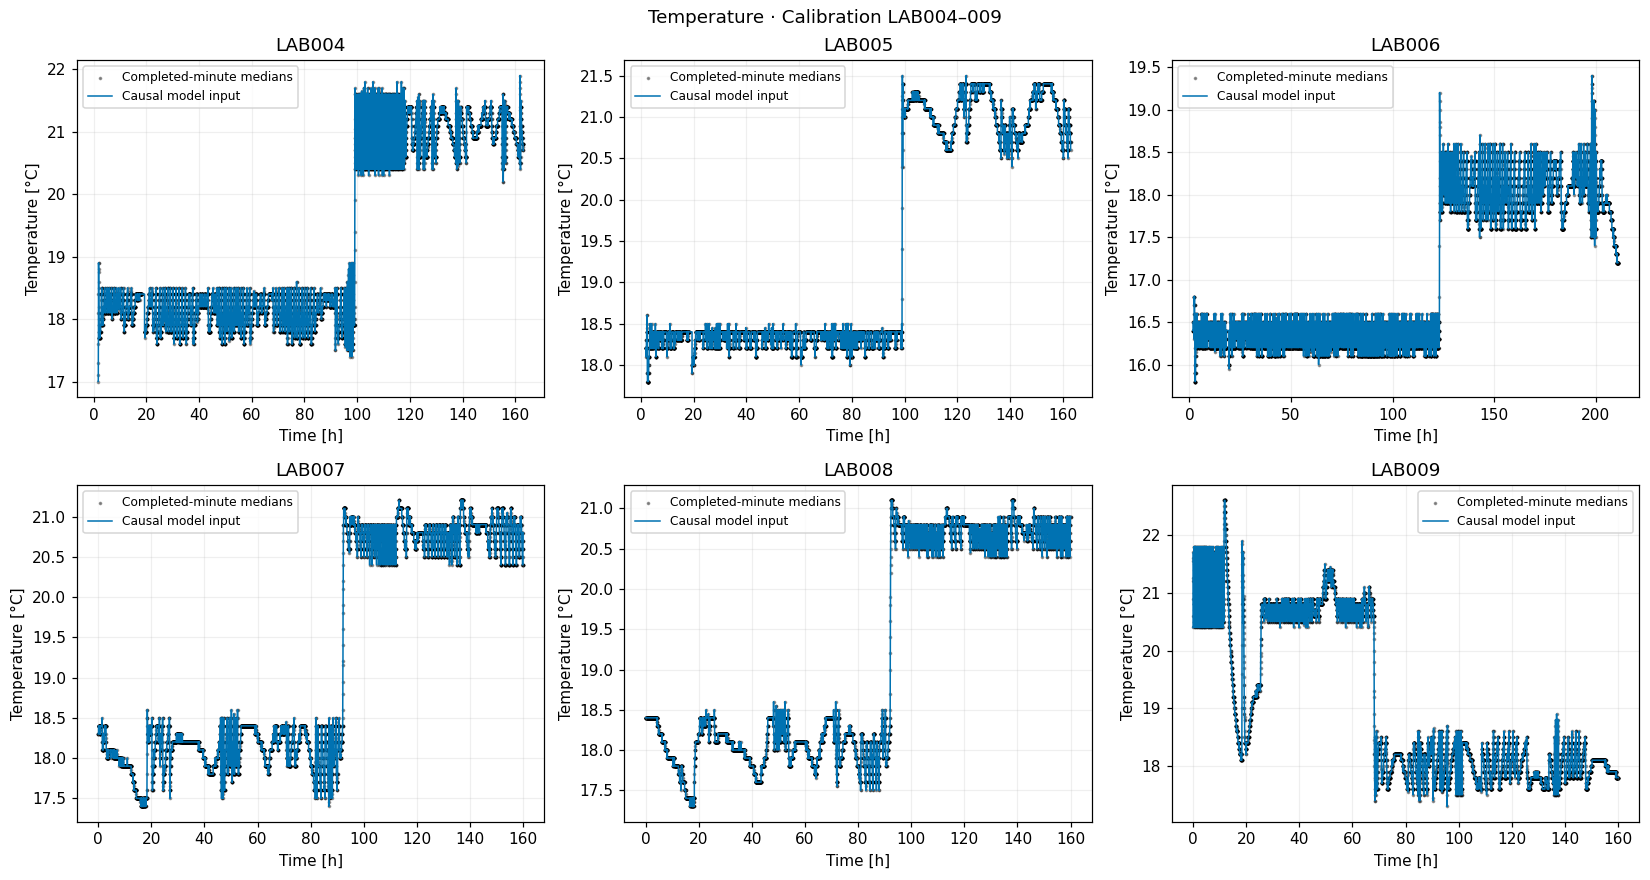

In [4]:
def temperature_panel(ax,batch,role=''):
 available,values=thermal_profiles[batch.batch]
 first,end=batch.time[[0,-1]]
 mask=(available>=first)&(available<=end)
 ax.scatter(available[mask],values[mask],s=2,c='black',alpha=.35,label='Completed-minute medians')
 start=propagation_start(batch)
 knots=np.r_[start,available[(available>start)&(available<end)],end]
 ax.step(knots,causal_temperature(batch,knots),where='post',c='#0072B2',lw=1,
         label='Causal model input')
 ax.set(title=batch.batch+role,xlabel='Time [h]',ylabel='Temperature [°C]')
 ax.grid(alpha=.2)
 ax.legend(loc='best',fontsize=8)

fig,axes=plt.subplots(2,3,figsize=(15,8))
for ax,batch in zip(axes.flat,treated):
 temperature_panel(ax,batch)
fig.suptitle('Temperature · Calibration LAB004–009',y=.99)
fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9)
plt.show()


## Calibración LAB004–009

El RMSE se calcula sobre las muestras posteriores a la inicial. Para YAN se usan los valores tratados que entraron al ajuste. En las evaluaciones posteriores, se usan las muestras de cada lote según la preparación del notebook 16.

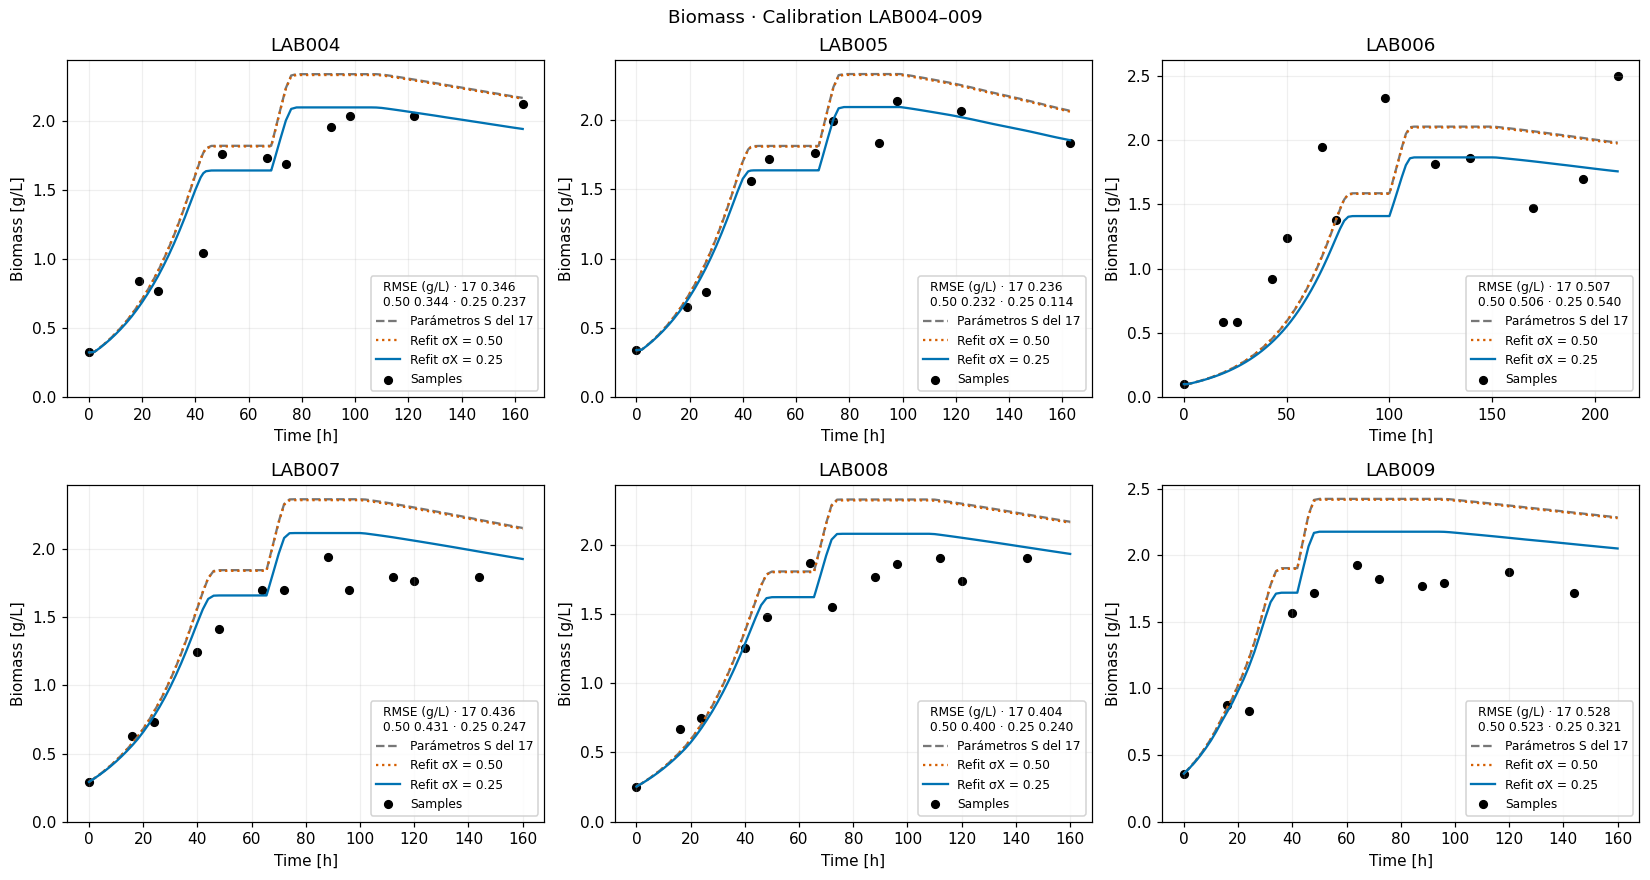

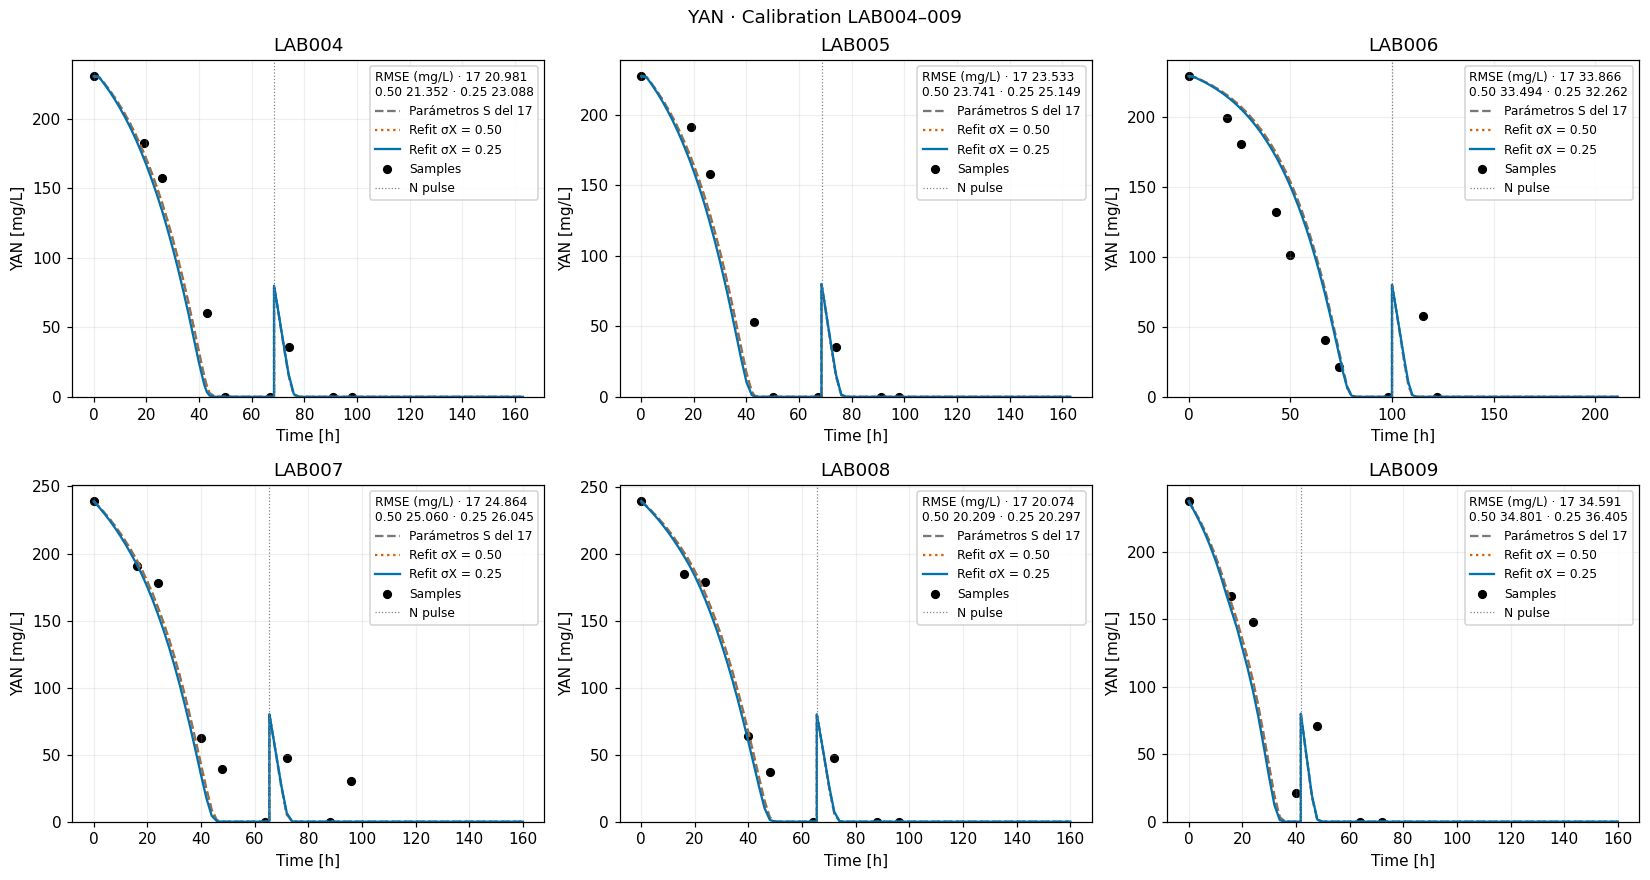

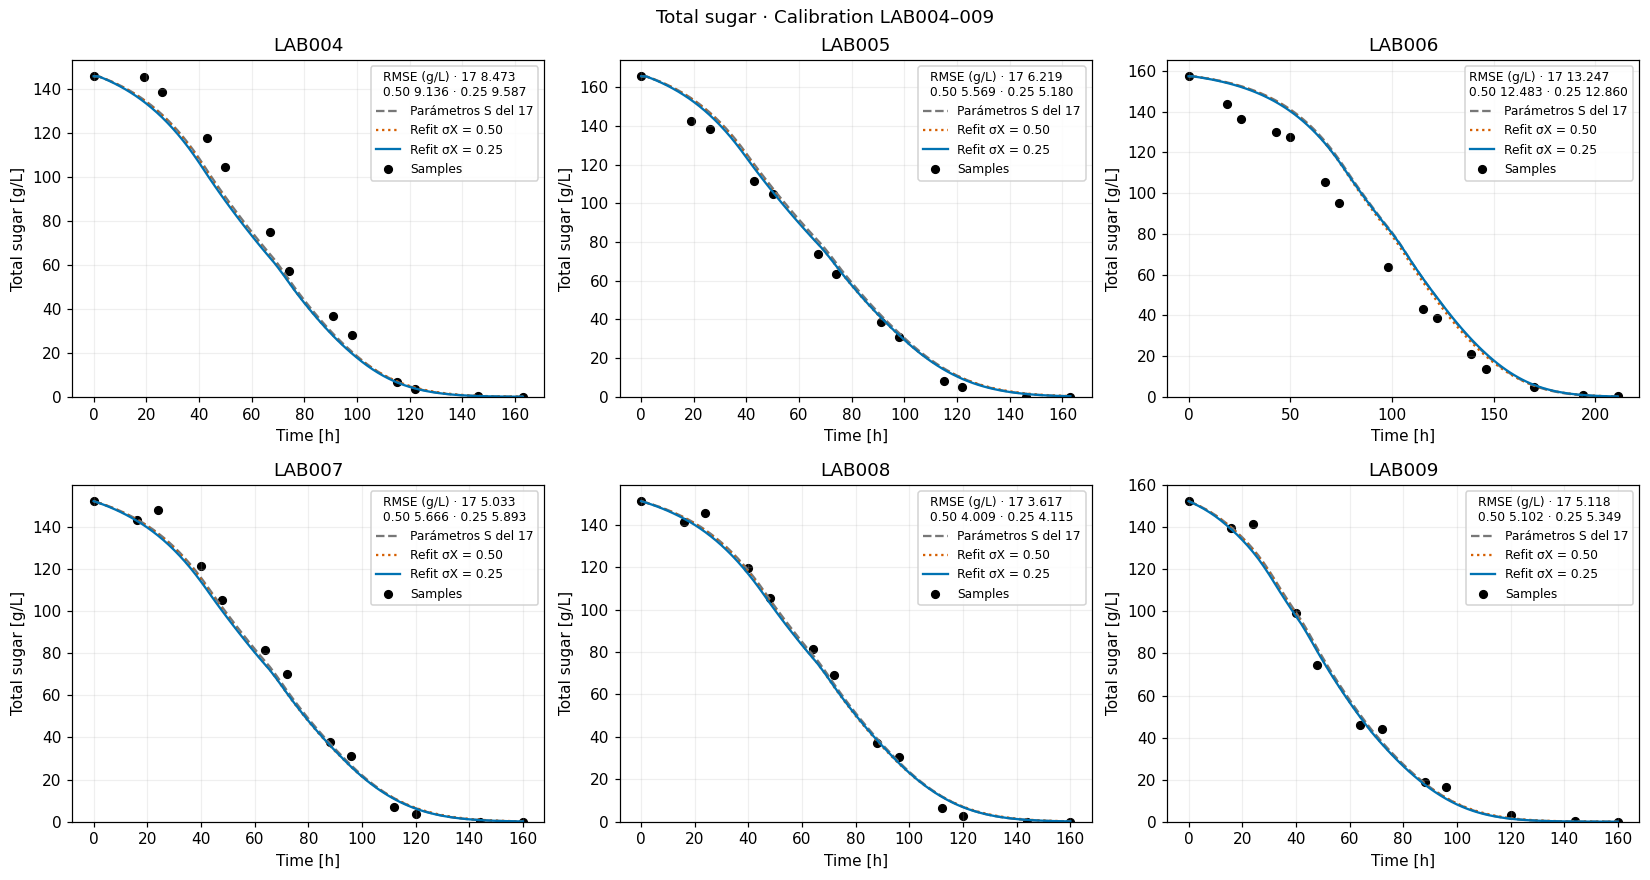

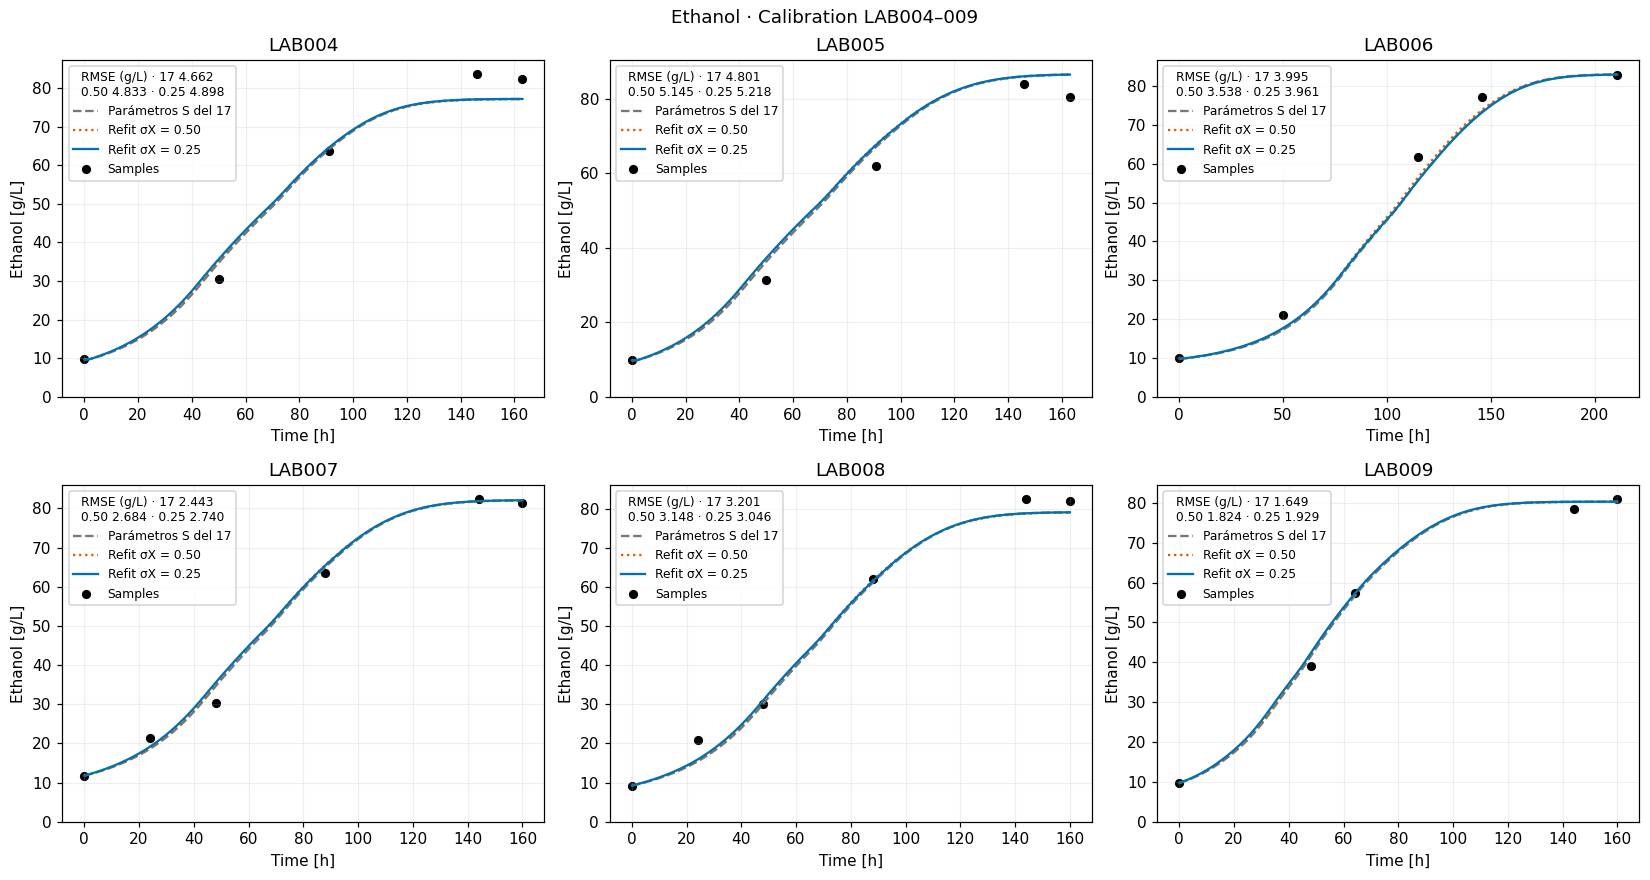

In [5]:
def legend_inside(ax):
 handles,labels=ax.get_legend_handles_labels()
 unique=dict(zip(labels,handles))
 legend=ax.legend(unique.values(),unique.keys(),loc='best',fontsize=8,framealpha=.85,
                  title=getattr(ax,'_rmse_text',None),title_fontsize=8)
 assert len(legend.get_texts())==len(unique)


styles = {published_label: dict(color='#777777', linestyle='--'),
          control_label: dict(color='#D55E00', linestyle=':'),
          weighted_label: dict(color='#0072B2', linestyle='-')}
paired_scores = []
biomass_errors = []


def plot_comparison(ax, traces, horizon):
 for label, trace in traces.items():
  window = trace.index <= horizon
  ax.plot(trace.index[window], trace[window], label=label, **styles[label])


def score_comparison(group, lab, state, unit, times, observed, predictions):
 if not len(times):
  return None
 rmse = {}
 for label, predicted in predictions.items():
  assert len(predicted)==len(times) and np.isfinite(predicted).all() and np.isfinite(observed).all()
  errors = predicted - observed
  rmse[label] = np.sqrt(np.mean(errors**2))
  paired_scores.append(dict(grupo=group, LAB=lab, variable=state, unidad=unit,
                            ajuste=label, n=len(times), RMSE=rmse[label], sesgo=errors.mean()))
  if state=='X' and group!='Calibración química':
   for time, sample, value in zip(times, observed, predicted):
    biomass_errors.append(dict(LAB=lab,t_h=time,ajuste=label,observada=sample,
                               predicha=value,error=value-sample))
 return (f'RMSE ({unit}) · 17 {rmse[published_label]:.3f}\n'
         f'0.50 {rmse[control_label]:.3f} · 0.25 {rmse[weighted_label]:.3f}')


def chemical_frames(lab, fitted, references):
 return {**{label: frames[lab] for label,frames in references.items()}, weighted_label: fitted[lab]}


for state,title,scale in [('X','Biomass',1),('N','YAN',1000),('S','Total sugar',1),('E','Ethanol',1)]:
 fig,axes=plt.subplots(2,3,figsize=(15,8))
 unit='mg/L' if state=='N' else 'g/L'
 for ax,batch in zip(axes.flat,treated):
  frames=chemical_frames(batch.batch,traincurves,reference_train)
  plot_comparison(ax, {label: with_jumps(frame)[state]*scale for label,frame in frames.items()}, batch.time[-1])
  measured,_=observed_state(batch,state,biomass_scales[weighted_label])
  used=np.isfinite(measured)&(batch.time>0)
  ax.scatter(batch.time[used],measured[used]*scale,c='black',s=25,label='Samples')
  initial=batch.initials
  initial_value=initial['G']+initial['F'] if state=='S' else initial[state]
  ax.scatter([0.],[initial_value*scale],c='black',s=25,label='Samples')
  predictions={label: frame[state].to_numpy()[used]*scale for label,frame in frames.items()}
  ax._rmse_text=score_comparison('Calibración química',batch.batch,state,unit,batch.time[used],
                                 measured[used]*scale,predictions)
  if state=='N':
   for time,dose in batch.pulses['N']:
    ax.axvline(time,c='gray',ls=':',lw=.8,label='N pulse')
  ax.set(title=batch.batch,xlabel='Time [h]',ylabel=f'{title} [{unit}]',ylim=(0,None))
  ax.grid(alpha=.2)
  legend_inside(ax)
 fig.suptitle(title+' · Calibration LAB004–009',y=.99)
 fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9)
 plt.show()


## Predicciones LAB016–021

LAB019–021 se usaron en el notebook 17 para calibrar el gas del modelo S. La biomasa de LAB016–021 se reserva para evaluar los dos ajustes químicos.

In [6]:
v=load(ROOT);LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018'];TRAIN=LABS[:3];HOLD=LABS[3:]
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','remaining_volume_L','co2_raw_g_l_h']);obs=observations(raw)
batches={};cores={};volumes={};caches={};activation={};entry=[]
for lab in LABS:
 b=v.batches[lab];ev=raw.loc[raw.lab.eq(lab)&raw.record_kind.eq('withdrawal_after')].sort_values('time_h');et=ev.time_h.to_numpy();vv=ev.remaining_volume_L.to_numpy()
 def volume(t,et=et,vv=vv):return np.r_[2.,vv][np.searchsorted(et,np.asarray(t),side='right')]
 volumes[lab]=volume
 if lab in TRAIN:b=replace(b,pulses={**b.pulses,'N':tuple((t,d*2/float(volume(t))) for t,d in b.pulses['N'])})
 if lab=='LAB017':b=replace(b,pulses={**b.pulses,'N':((min(t for t,d in b.pulses['N']),sum(d for t,d in b.pulses['N'])),)})
 if lab=='LAB021':b=replace(b,initials={**b.initials,'X':9.*.03})
 register_temperature(lab,v.raw_temperature[lab])
 batches[lab]=b;cores[lab]=simulate(b,theta)
 entry.append(dict(LAB=lab,**b.initials,pulsos=b.pulses['N'],corte_h=v.horizons[lab]))
 obs[lab]=obs[lab].loc[obs[lab].time_h.between(0,v.horizons[lab])].copy()
display(pd.DataFrame(entry))

from types import FunctionType

def gas_inputs(frames, batch_inputs, chemical_parameters, *, horizon=None):
 source={}; active={}
 for lab,trajectory in frames.items():
  frame=with_jumps(trajectory)
  batch=batch_inputs[lab]
  begin=propagation_start(batch)
  end=float(frame.index[-1]) if horizon is None else horizon
  available,_=thermal_profiles[lab]
  times=np.unique(np.round(np.r_[np.arange(begin,end,.1),end,available[(available>begin)&(available<end)]],12))
  assert np.min(np.diff(times))>1e-10
  midpoints=(times[:-1]+times[1:])/2
  interval_temperatures=causal_temperature(batch,times[:-1])
  rates=[0.]
  p=parameter_vector(chemical_parameters)
  for time,temperature in zip(midpoints,interval_temperatures):
   y=np.array([np.interp(time,frame.index,frame[state]) for state in STATES])
   mu,beta,_,_=sugar_terms(y,p,temperature)
   rates.append((mu/12.72+beta/1.05)*y[0])
  source[lab]=(times,np.asarray(rates))
  initial_sugar=batch.initials['G']+batch.initials['F']
  consumed=initial_sugar-np.interp(np.r_[begin,midpoints],frame.index,frame.S)
  z=np.clip((consumed-5.)/5.,0.,1.)
  active[lab]=z*z*(3.-2.*z)
  assert np.all(active[lab][consumed<=5.]==0) and np.all(active[lab][consumed>=10.]==1)
 return source,active

PCO2_BAR=1.0
ETHANOL_G_L_PER_VOL_PERCENT=7.8924

def saturation(T,E,S):
 a=np.maximum(E,0)/ETHANOL_G_L_PER_VOL_PERCENT
 return 3.295*np.exp((7e-5*a-.02905)*np.asarray(T)-.0179*a-.00111*np.maximum(S,0))*PCO2_BAR

def configure_gas(frames):
 global gas_equilibrium
 gas_equilibrium={}
 for lab,f in frames.items():
  times=caches[lab][0]
  ff=with_jumps(f)
  batch=batches[lab]
  T=causal_temperature(batch,times)
  E=np.interp(times,ff.index,ff.E)
  S=np.interp(times,ff.index,ff.S)
  gas_equilibrium[lab]=(T,E,S,saturation(T,E,S))

def gas(lab,k,gain=1,activated=True,substeps=1):
 t,source=caches[lab]
 source=source*activation[lab] if activated else source.copy()
 T,E,S,sat=gas_equilibrium[lab]
 cd=np.zeros(len(t));qout=np.zeros(len(t));acc=np.zeros(len(t))
 qout[0]=max(source[0]-k*sat[0],0.)
 for i,dt in enumerate(np.diff(t),1):
  qp=source[i];previous=cd[i-1];current=previous
  for j in range(substeps):
   h=dt/substeps;fraction=(j+.5)/substeps;cs=saturation(T[i-1],E[i-1]*(1-fraction)+E[i]*fraction,S[i-1]*(1-fraction)+S[i]*fraction)
   if current>cs:
    current=cs+(current-cs)*np.exp(-k*h)
   else:
    D=cs-current
    if qp<=0 or D<=0:delta=0.
    elif k*D<=qp:delta=D*(-np.expm1(-k*h))
    else:
     crossing=(D-qp/k)/qp;linear=min(h,crossing);delta=qp*linear
     if crossing<h:delta+=(qp/k)*(-np.expm1(-k*(h-crossing)))
    current+=delta
  cd[i]=current;acc[i]=(current-previous)/dt;qout[i]=qp-acc[i]
 assert cd.min()>=-1e-12 and qout.min()>-1e-10, (lab,cd.min(),qout.min())
 assert np.max(abs(np.diff(cd)-np.diff(t)*(source[1:]-qout[1:])))<1e-10
 return pd.DataFrame(dict(qprod=source,Cd=cd,Csat=sat,T=T,E=E,S=S,qgas=qout,qpred=gain*qout),index=t)

KLA,GAIN=(0.13796553316180868, 0.6586783889606775)
reference_cores={label: {lab: simulate(batch, p) for lab,batch in batches.items()}
                 for label,p in parameters.items() if label != weighted_label}

def gas_curves(frames, batch_inputs, chemical_parameters, *, horizon=None):
 source,active=gas_inputs(frames,batch_inputs,chemical_parameters,horizon=horizon)
 context=dict(globals(),batches=batch_inputs,caches=source,activation=active)
 FunctionType(configure_gas.__code__,context)(frames)
 predict=FunctionType(gas.__code__,context,argdefs=gas.__defaults__)
 return {lab: predict(lab,KLA,GAIN) for lab in frames}


caches,activation=gas_inputs(cores,batches,theta)
curves=gas_curves(cores,batches,theta)
reference_gas={label: gas_curves(frames,batches,parameters[label])
               for label,frames in reference_cores.items()}
metrics=[]
for lab in LABS:
 o=obs[lab];f=curves[lab];e=np.interp(o.time_h,f.index,f.qpred)-o.co2_raw_g_l_h
 metrics.append(dict(LAB=lab,rol='Calibración gas' if lab in TRAIN else 'Holdout gas',n=len(o),RMSE=np.sqrt(np.mean(e*e)),sesgo=np.mean(e)))
metrics=pd.DataFrame(metrics);display(metrics);display(metrics.groupby('rol')[['RMSE','sesgo']].mean())

display(pd.DataFrame([dict(LAB=lab,inicio_5g_h=float(caches[lab][0][np.flatnonzero(activation[lab]>0)[0]]),completa_10g_h=float(caches[lab][0][np.flatnonzero(activation[lab]>=1)[0]])) for lab in LABS]))


,LAB,X,N,G,F,E,pulsos,corte_h
0,LAB019,0.283162,0.230025,79.190000,78.970000,12.075372,"((64.33333333333277, 0.08648648648648648),)",166.000000
1,LAB020,0.153342,0.225556,77.940000,79.520000,11.917524,"((71.66666666666694, 0.08888888888888889),)",172.333333
2,LAB021,0.270000,0.231202,80.190000,81.040000,11.759676,"((47.5, 0.08648648648648648),)",166.000000
3,LAB016,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93555555555583, 0.14),)",151.100000
4,LAB017,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.933611111110835, 0.28),)",141.000000
5,LAB018,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93166666666694, 0.14),)",141.000000


,LAB,rol,n,RMSE,sesgo
0,LAB019,Calibración gas,166,0.129681,0.017550
1,LAB020,Calibración gas,172,0.075830,0.036230
2,LAB021,Calibración gas,166,0.190435,0.021677
3,LAB016,Holdout gas,152,0.149698,0.005713
4,LAB017,Holdout gas,141,0.147635,-0.032279
5,LAB018,Holdout gas,141,0.137578,-0.006712


,RMSE,sesgo
rol,,
Calibración gas,0.131982,0.025152
Holdout gas,0.144970,-0.011093


,LAB,inicio_5g_h,completa_10g_h
0,LAB019,10.083333,17.383333
1,LAB020,17.466667,28.516667
2,LAB021,9.516667,16.016667
3,LAB016,6.533333,11.583333
4,LAB017,6.616667,11.750000
5,LAB018,6.533333,11.583333


## Holdout LAB022–024

Predicción del modelo S con los parámetros químicos del notebook y los parámetros de gas ya guardados en su versión ejecutada. La simulación abarca hasta las 190 h. Las condiciones iniciales siguen las del notebook 13. La química de inoculación y la primera muestra de biomasa a las 0,25 h inicializan la simulación. Para el etanol inicial se usan 10,010194 g/L. La temperatura proviene del respaldo del ensayo.

En la hora registrada de nutrición se aplica un pulso de 1 g de SFX y 0,4 g de FDA por lote. Con el volumen remanente y la conversión del notebook 13, el aporte nominal es 99,9 mg N/L. Las muestras posteriores se usan para evaluar las predicciones en sus horas de toma. El flujo se compara en ventanas de 30 minutos con observaciones reales válidas. Las curvas de etanol y CO₂ disuelto muestran las predicciones disponibles para esas variables.

El crecimiento se detiene cuando se agota el azúcar total. Se usa el mismo integrador químico para todos los lotes.

La última fila de las figuras corresponde a LAB022–024. Sus paneles de flujo muestran promedios de 30 minutos. Las filas previas usan el soporte de medición de sus ensayos.

In [7]:

import nbformat

instrument = json.loads((ROOT / "configs/co2_instrument.json").read_text(encoding="utf-8"))
prep_path = ROOT / "notebooks/preparing_data/lab022_024_data.source.ipynb"
prep_nb = nbformat.read(prep_path, as_version=4)
sample_code = [cell.source for cell in prep_nb.cells if cell.cell_type == "code" and
               any(marker in cell.source for marker in
                   ("workbook = data_dir /", "y15_sources = {", "oculyze_frames = []"))]
assert len(sample_code) == 3
prepared = {}
for source in sample_code:
    python_source = "\n".join(line for line in source.splitlines() if not line.startswith("%"))
    exec(compile(python_source, str(prep_path), "exec"), prepared)

holdout_labs = prepared["labs"]
holdout_biomass = prepared["oculyze"].assign(X_g_L=lambda f: .03 * f["Viable concentration"])
holdout_chemistry = prepared["chemistry"]
holdout_nutrition = (prepared["nutrition"] - prepared["inoculation"]).dt.total_seconds() / 3600
holdout_horizon = 190.
# Dosis confirmada por lote. Equivalente de YAN de SFX y fracción de N en FDA.
pulse_mass_n_g = 1.0 * .10 + .4 * (2 * 14.007 / 132.1)

reactors = prepared["experiments"]["Fermentador"]
reactor_map = pd.Series(reactors.index, index=reactors)
def read_holdout_backup(filename, value, *, include_before_start=False):
    frame = pd.read_csv(prepared["data_dir"] / filename,
                        usecols=["timestamp", "fermentador", value], parse_dates=["timestamp"])
    frame["lab"] = frame["fermentador"].map(reactor_map)
    frame["h"] = (frame["timestamp"] - frame["lab"].map(prepared["inoculation"])).dt.total_seconds() / 3600
    return (frame if include_before_start else frame.loc[frame["h"].ge(0)]).sort_values("h")

holdout_temperature = read_holdout_backup("backup_global_temperatura.csv", "T", include_before_start=True)
holdout_raw_flow = read_holdout_backup("backup_global_co2.csv", "flow_sccm")
mass_factor = 44.0095 * 60 * instrument["co2_correction_factor"] / (1000 * 24.16)
holdout_batches, holdout_flow, pulse_rows = {}, {}, []
for lab in holdout_labs:
    samples = prepared["offline"].loc[prepared["offline"]["lab"].eq(lab)]
    withdrawals = samples.loc[samples["Observaciones"].eq("se quitan 50ml"), "hours"].to_numpy()
    initial_volume = float(prepared["experiments"].at[lab, "Volumen_Inicial_L"].removesuffix("L"))
    pulse_h = holdout_nutrition[lab]
    pulse_volume = initial_volume - .05 * np.searchsorted(withdrawals, pulse_h, side="right")
    pulse_n = pulse_mass_n_g / pulse_volume
    start_sample = holdout_biomass.loc[holdout_biomass["lab"].eq(lab) &
                                       holdout_biomass["sample"].eq("01")].iloc[0]
    holdout_start = float(start_sample["hours"])
    assert holdout_start == .25
    chem = holdout_chemistry.loc[holdout_chemistry["lab"].eq(lab)]
    initial = chem.loc[chem["sample"].eq("01")].iloc[0]
    initials = {"X": start_sample["X_g_L"], "N": initial["YAN for plot"] / 1000,
                "G": initial["GLUCOSE-320"], "F": initial["Fructose (derived)"], "E": 10.010194}
    biomass_h = holdout_biomass.loc[holdout_biomass["lab"].eq(lab), "hours"]
    # Se incluyen las horas de muestreo para evaluar la solución directamente.
    times = np.unique(np.r_[np.arange(holdout_start, holdout_horizon, .1), holdout_horizon, pulse_h,
                           chem.loc[chem["hours"].ge(holdout_start), "hours"], biomass_h])
    temp = holdout_temperature.loc[holdout_temperature.lab.eq(lab)].rename(columns={'h':'t_h'})
    register_temperature(lab,temp)
    holdout_batches[lab] = kin.BatchData(
        medium="natural", batch=lab, time=times, temperature_c=np.full(len(times),np.nan),
        pulses={"N": ((pulse_h, pulse_n),)}, observations={}, initials=initials,
    )
    pulse_rows.append({"LAB": lab, "Pulso [h]": pulse_h, "Volumen [L]": pulse_volume,
                       "Aporte [mg N/L]": 1000 * pulse_n})
    raw = holdout_raw_flow.loc[holdout_raw_flow["lab"].eq(lab) &
                               holdout_raw_flow["h"].gt(0)].copy()
    assert raw["h"].max() >= holdout_horizon
    raw["bin"] = np.ceil(raw["h"] / .5 - 1e-10).astype(int)
    holdout_sample_volumes = initial_volume - .05 * np.searchsorted(withdrawals, raw["h"], side="right")
    raw["mass_flow"] = raw["flow_sccm"] * mass_factor / holdout_sample_volumes
    means = {}
    for index, window in raw.groupby("bin"):
        end = index * .5
        if end > holdout_horizon:
            break
        gaps = np.diff(np.r_[end - .5, window["h"], end])
        valid = len(window) >= 30 and gaps.max() <= 2 / 60 + 1e-10
        means[end] = window["mass_flow"].mean() if valid else np.nan
    holdout_flow[lab] = pd.Series(means).reindex(np.arange(.5, holdout_horizon + .5, .5))
display(pd.DataFrame(pulse_rows).set_index("LAB").round(3))

,Pulso [h],Volumen [L],Aporte [mg N/L]
LAB,,,
LAB022,113.633,1.85,99.906
LAB023,113.783,1.85,99.906
LAB024,113.883,1.85,99.906


In [8]:
holdout_kinetic = {lab: simulate(batch,theta) for lab,batch in holdout_batches.items()}
reference_holdout = {label: {lab: simulate(batch,p) for lab,batch in holdout_batches.items()}
                     for label,p in parameters.items() if label != weighted_label}
for frames in [holdout_kinetic,*reference_holdout.values()]:
    for lab,frame in frames.items():
        [jump] = frame.attrs["pulse_jumps"]
        np.testing.assert_allclose([jump["t"], jump["after"][1]-jump["before"][1]],
                                   holdout_batches[lab].pulses["N"][0], atol=1e-12)

holdout_gas = gas_curves(holdout_kinetic,holdout_batches,theta,horizon=holdout_horizon)
reference_holdout_gas = {label: gas_curves(frames,holdout_batches,parameters[label],horizon=holdout_horizon)
                         for label,frames in reference_holdout.items()}

def gas_window_means(frames):
    means = {}
    for lab,curve in frames.items():
        times = curve.index.to_numpy()
        cumulative = np.r_[0.,np.cumsum(np.diff(times)*curve["qpred"].to_numpy()[1:])]
        ends = holdout_flow[lab].index.to_numpy()
        ends = ends[ends-.5 >= times[0]]
        means[lab] = pd.Series((np.interp(ends,times,cumulative) -
                                np.interp(ends-.5,times,cumulative))/.5, index=ends)
    return means

holdout_mean_gas = gas_window_means(holdout_gas)
reference_mean_gas = {label: gas_window_means(frames) for label,frames in reference_holdout_gas.items()}


## Temperatura · LAB016–024

Las medianas del minuto aparecen en la hora de cierre. La línea escalonada muestra el valor disponible para el modelo.

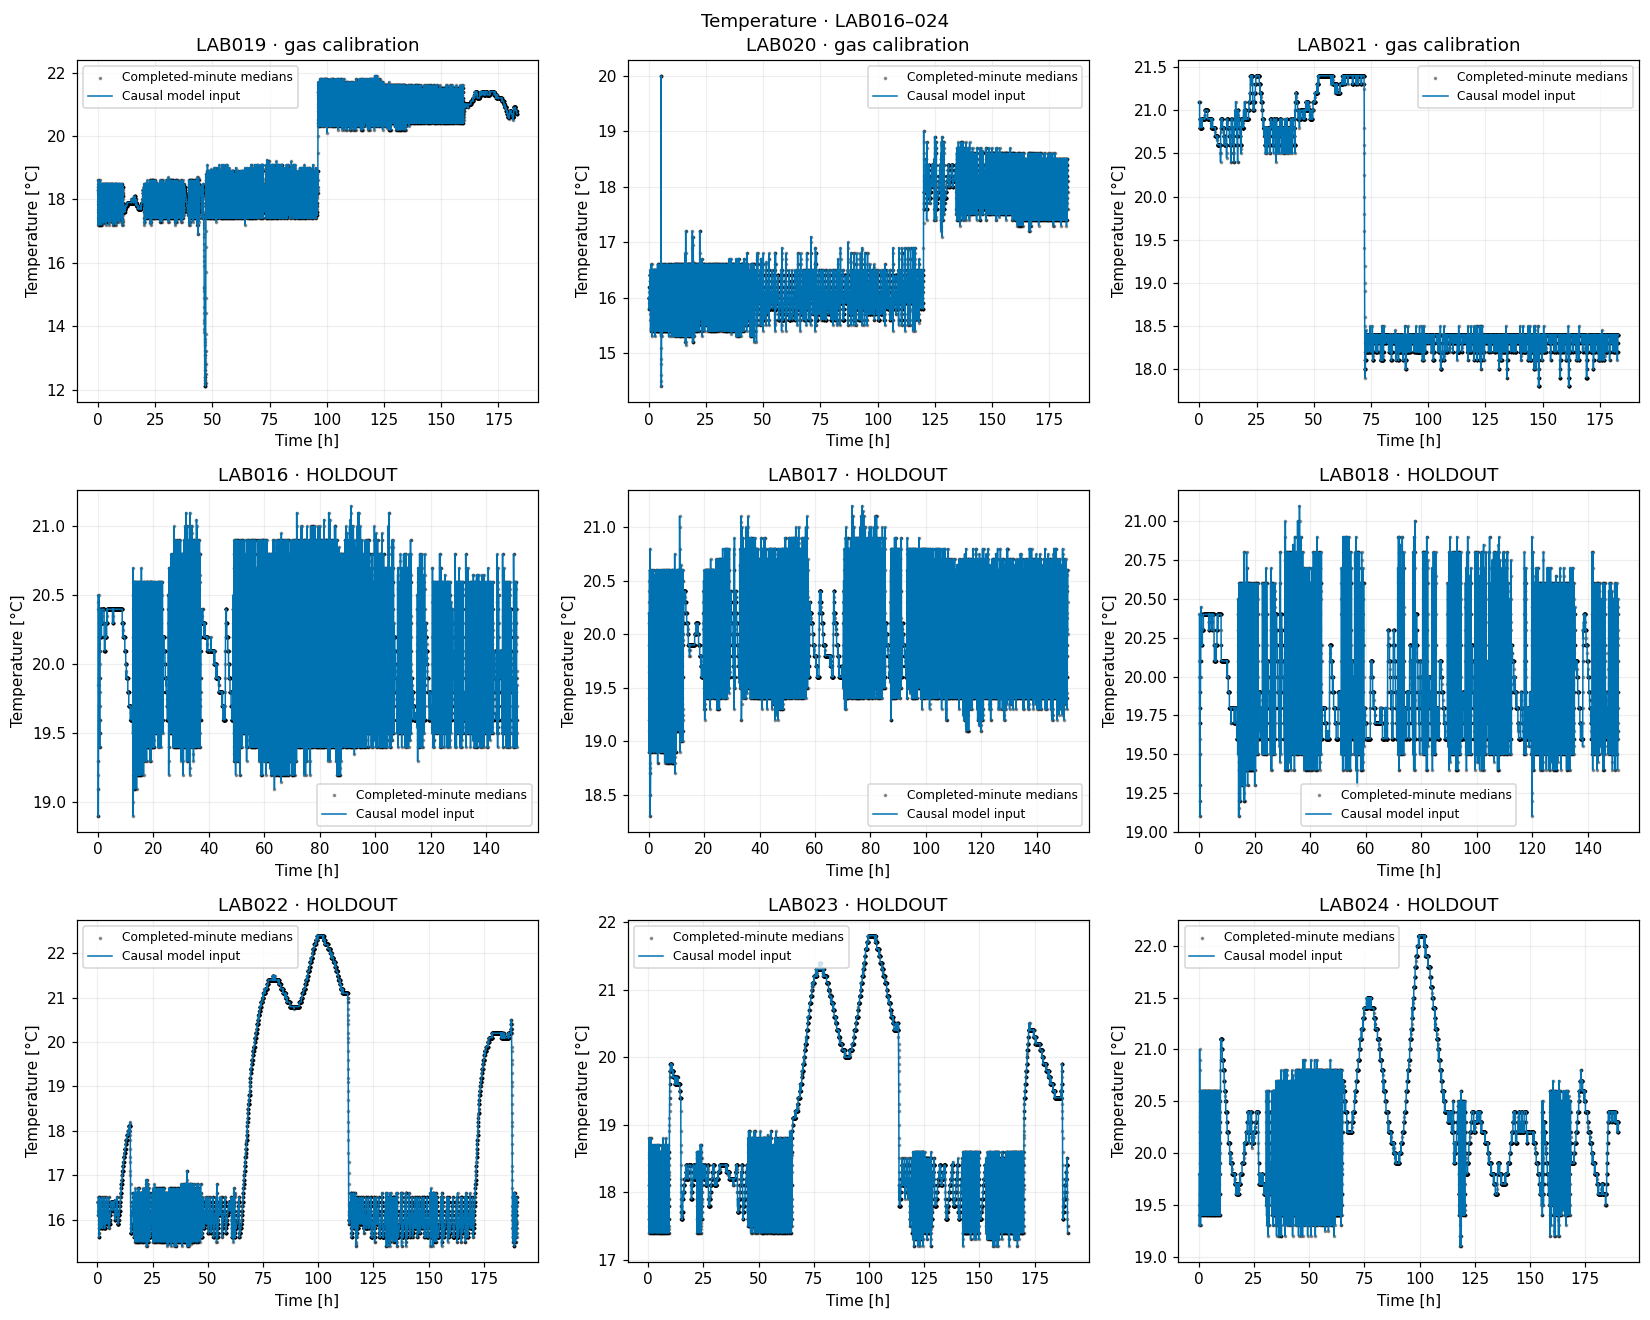

,espera_min,temperatura_inicial_C,minutos_con_datos,max_retencion_min
LAB,,,,
LAB004,107.0,17.0,9607,67.0
LAB005,107.0,18.2,9606,68.0
LAB006,108.0,16.4,12485,68.0
LAB007,0.0,18.3,9600,1.0
LAB008,0.0,18.4,9600,1.0
LAB009,0.0,20.4,9600,1.0
LAB019,0.0,17.2,10984,1.0
LAB020,0.0,15.8,10984,1.0
LAB021,0.0,21.1,10984,1.0


TEMPERATURE_AUDIT_JSON [{"LAB": "LAB004", "espera_min": 107.0, "temperatura_inicial_C": 17.0, "minutos_con_datos": 9607, "max_retencion_min": 67.00000000000003}, {"LAB": "LAB005", "espera_min": 107.0, "temperatura_inicial_C": 18.2, "minutos_con_datos": 9606, "max_retencion_min": 67.99999999999997}, {"LAB": "LAB006", "espera_min": 108.0, "temperatura_inicial_C": 16.4, "minutos_con_datos": 12485, "max_retencion_min": 67.99999999999997}, {"LAB": "LAB007", "espera_min": 0.0, "temperatura_inicial_C": 18.3, "minutos_con_datos": 9600, "max_retencion_min": 1.0000000000007958}, {"LAB": "LAB008", "espera_min": 0.0, "temperatura_inicial_C": 18.4, "minutos_con_datos": 9600, "max_retencion_min": 1.0000000000007958}, {"LAB": "LAB009", "espera_min": 0.0, "temperatura_inicial_C": 20.4, "minutos_con_datos": 9600, "max_retencion_min": 1.0000000000007958}, {"LAB": "LAB019", "espera_min": 0.0, "temperatura_inicial_C": 17.2, "minutos_con_datos": 10984, "max_retencion_min": 1.0000000000007958}, {"LAB": "LAB

In [9]:
fig,axes=plt.subplots(3,3,figsize=(15,12))
for ax,lab in zip(axes.flat,[*LABS,*holdout_labs]):
 batch=(batches if lab in LABS else holdout_batches)[lab]
 temperature_panel(ax,batch,' · gas calibration' if lab in TRAIN else ' · HOLDOUT')
fig.suptitle('Temperature · LAB016–024',y=.99)
fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9)
plt.show()

temperature_audit=[]
for batch in [*treated,*batches.values(),*holdout_batches.values()]:
 available,values=thermal_profiles[batch.batch]
 first,end=batch.time[[0,-1]]
 begin=propagation_start(batch)
 updates=available[(available>begin)&(available<=end)]
 assert len(updates)>0 and np.isfinite(causal_temperature(batch,updates)).all()
 # Compare against the online lookup immediately before and after window closure.
 probes=updates[::max(1,len(updates)//20)]
 positions=np.searchsorted(available,probes)
 np.testing.assert_array_equal(causal_temperature(batch,probes),values[positions])
 np.testing.assert_array_equal(causal_temperature(batch,probes-1e-6),values[positions-1])
 temperature_audit.append(dict(LAB=batch.batch,espera_min=(begin-first)*60,
    temperatura_inicial_C=causal_temperature(batch,begin),
    minutos_con_datos=len(updates),
    max_retencion_min=np.diff(np.r_[begin,updates,end]).max()*60))
display(pd.DataFrame(temperature_audit).set_index('LAB').round(3))
print('TEMPERATURE_AUDIT_JSON',json.dumps(temperature_audit))


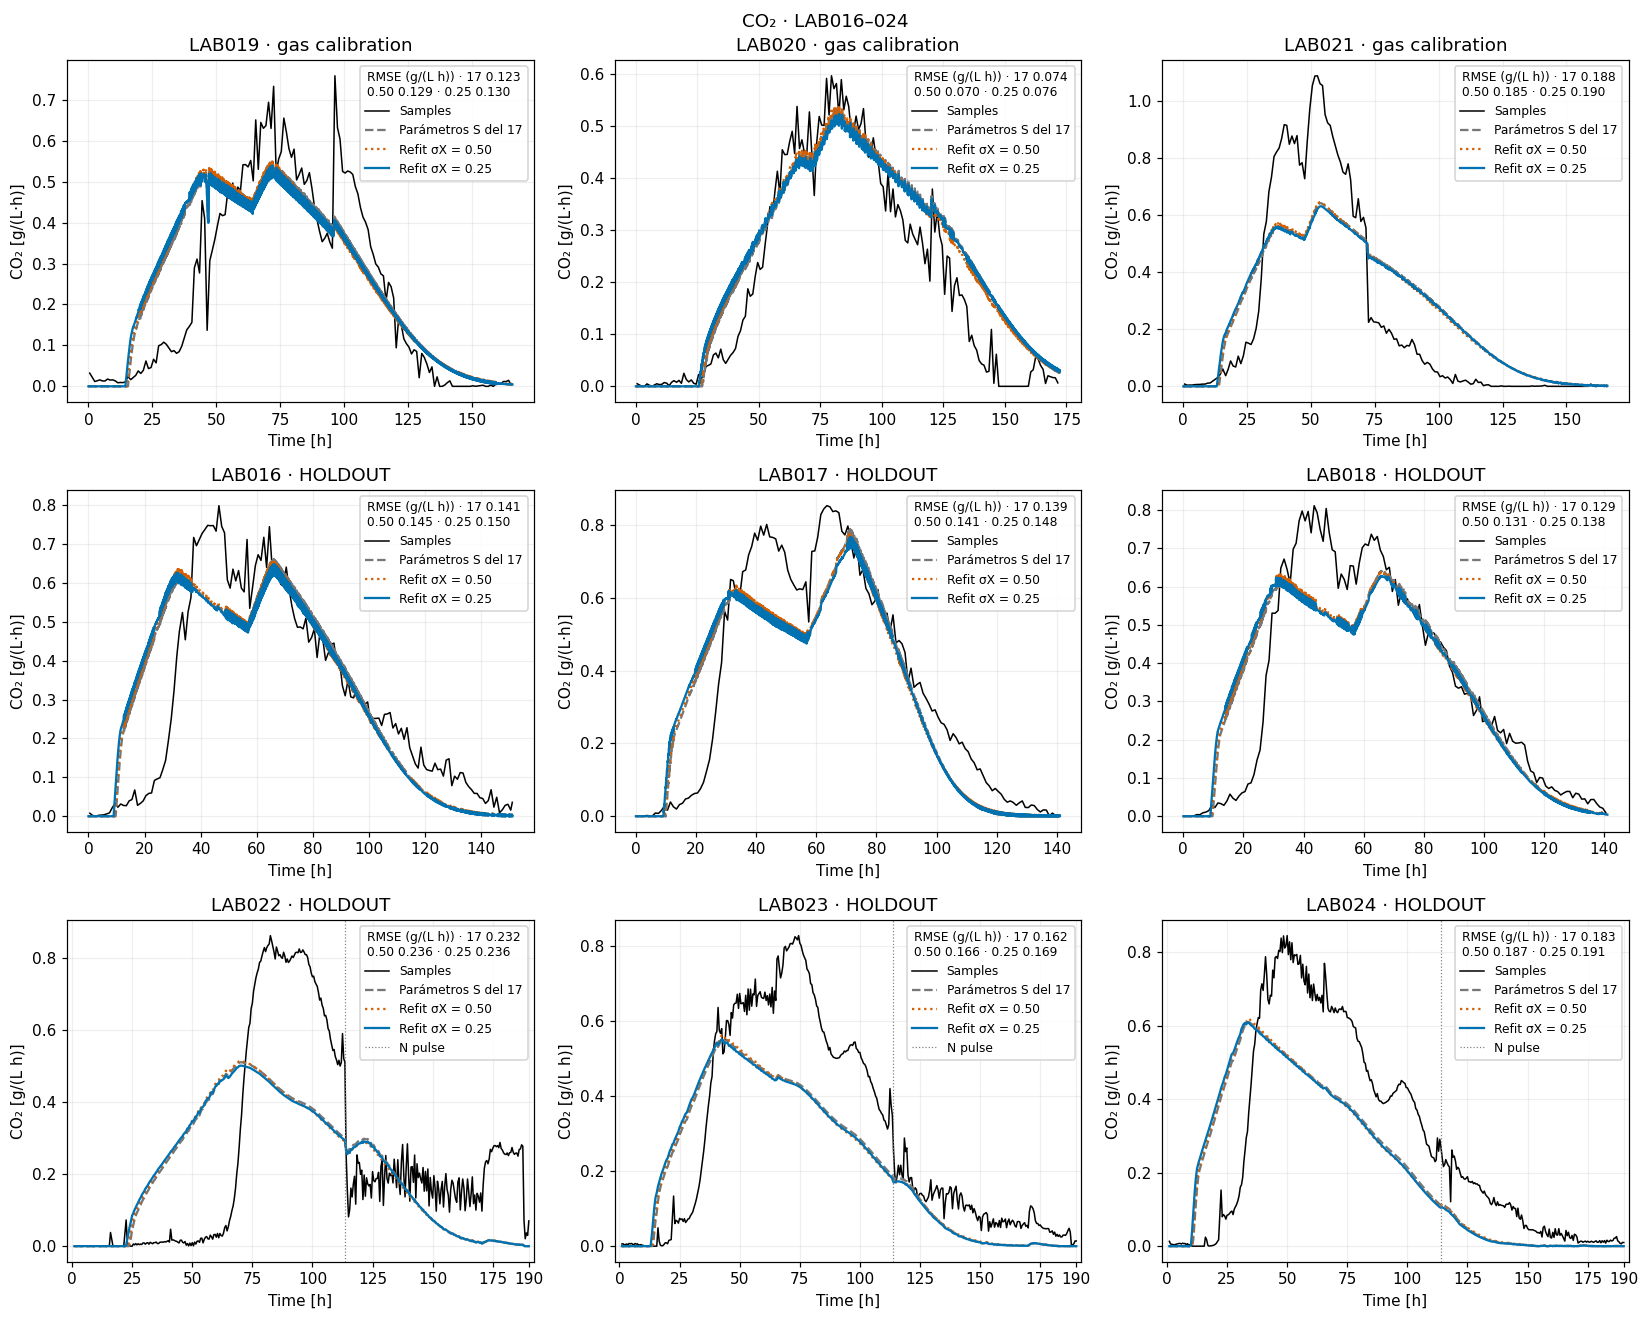

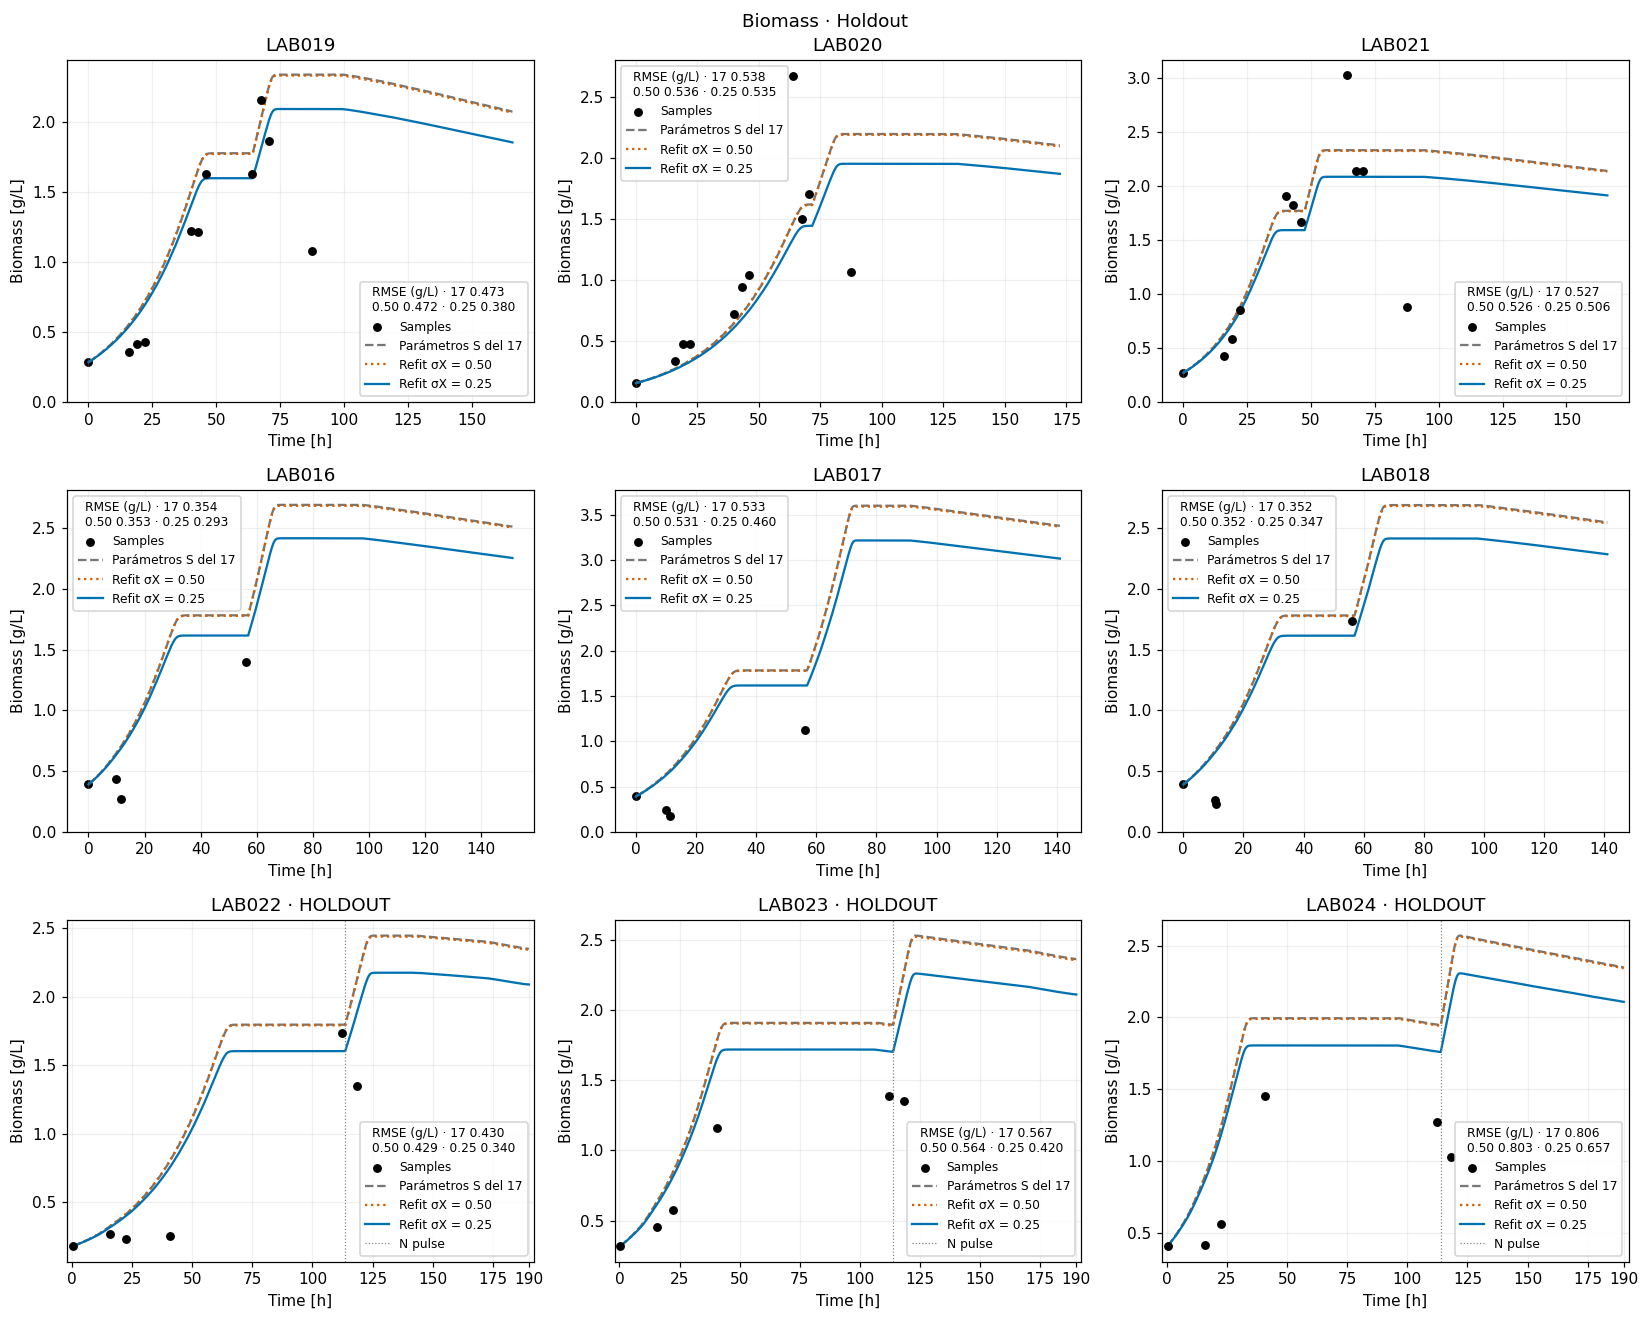

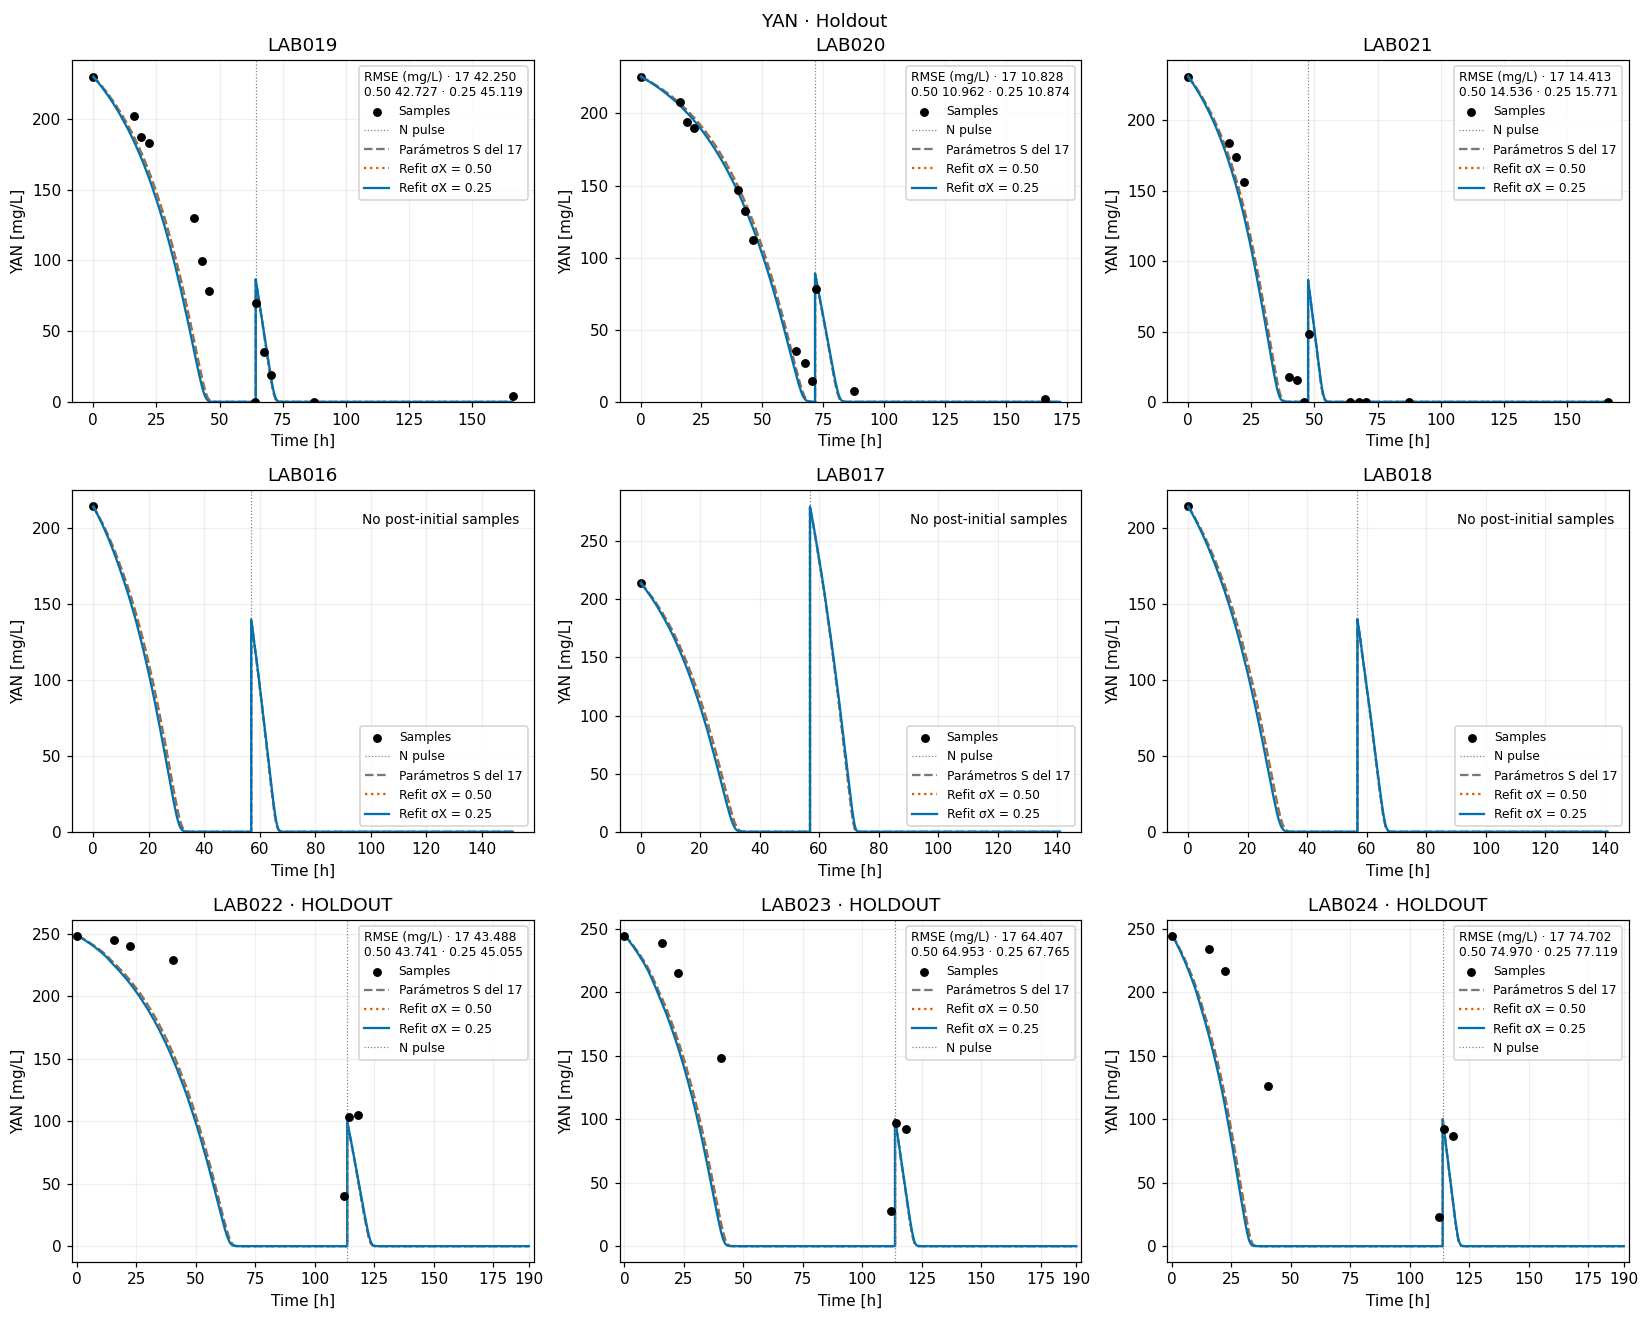

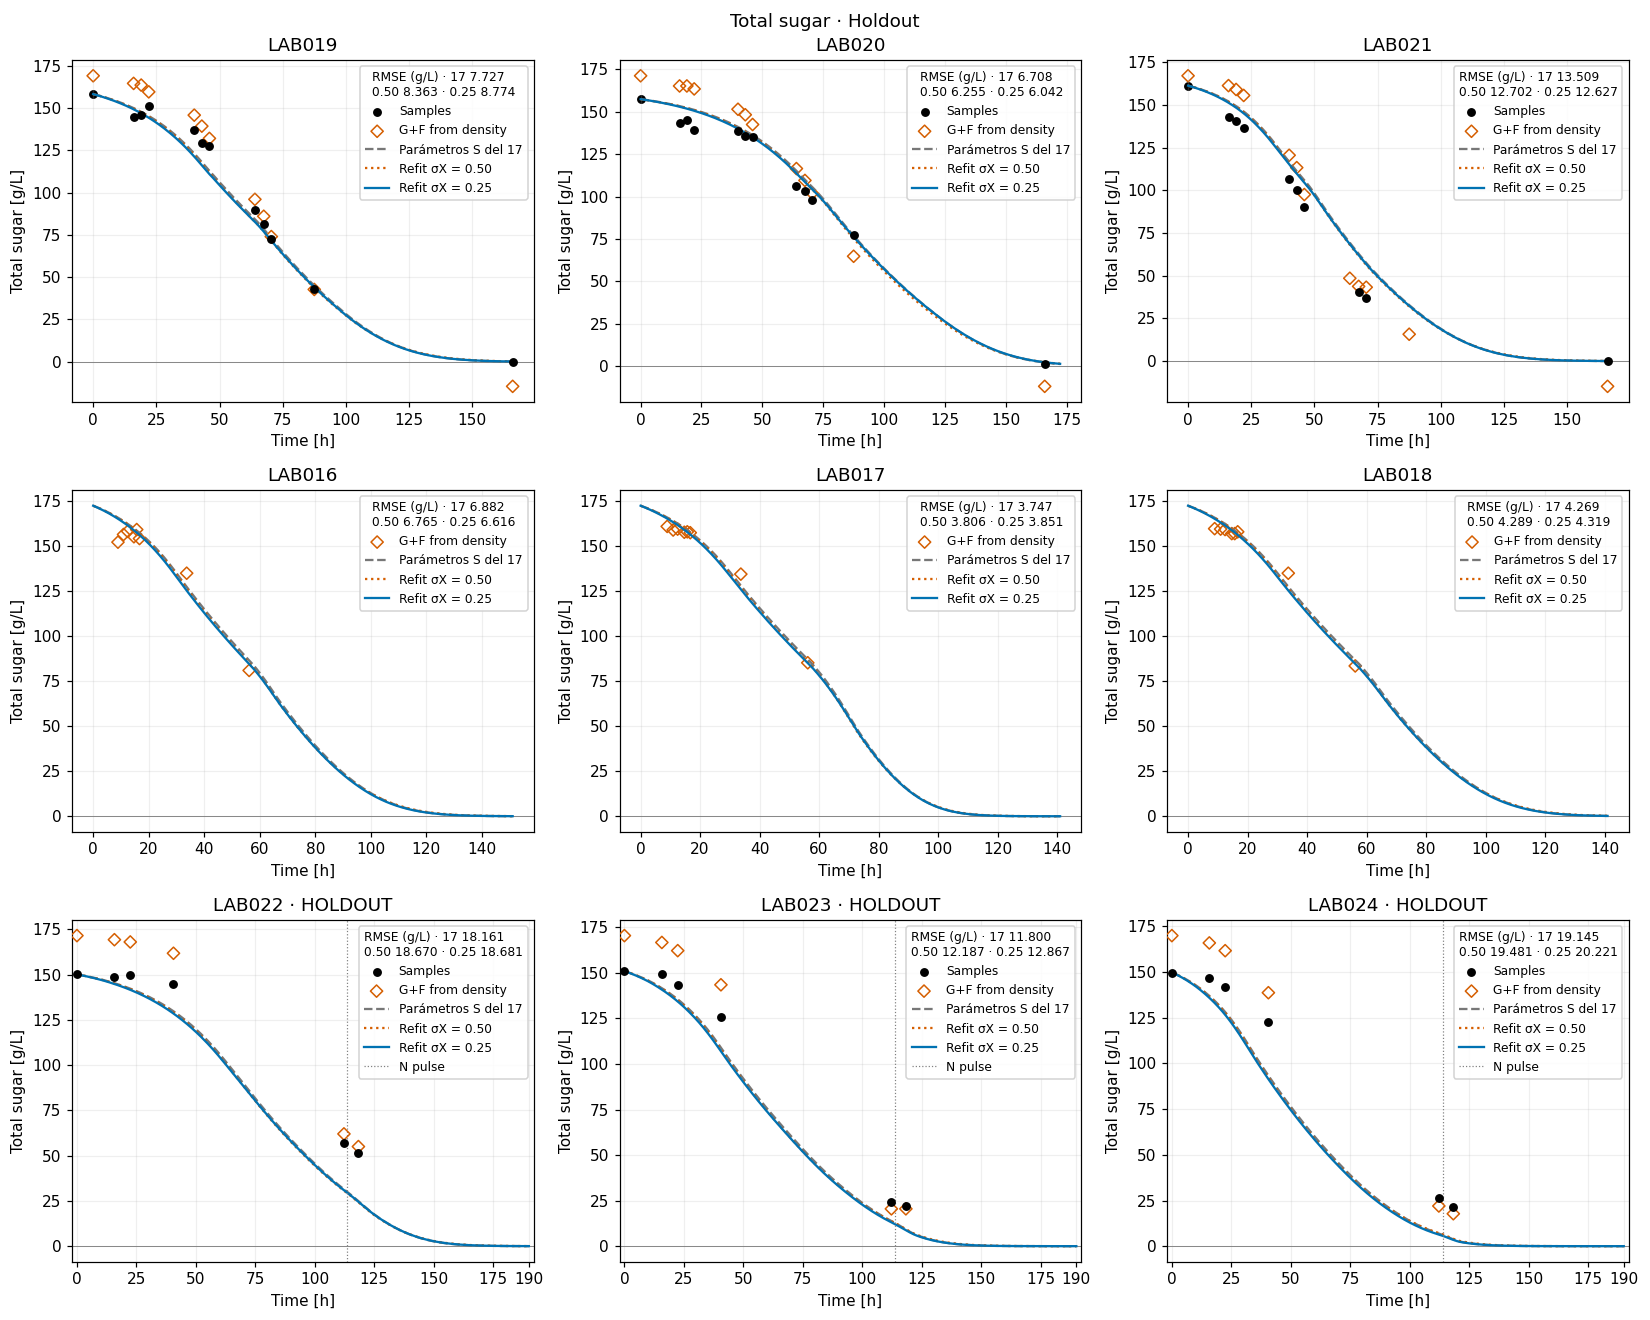

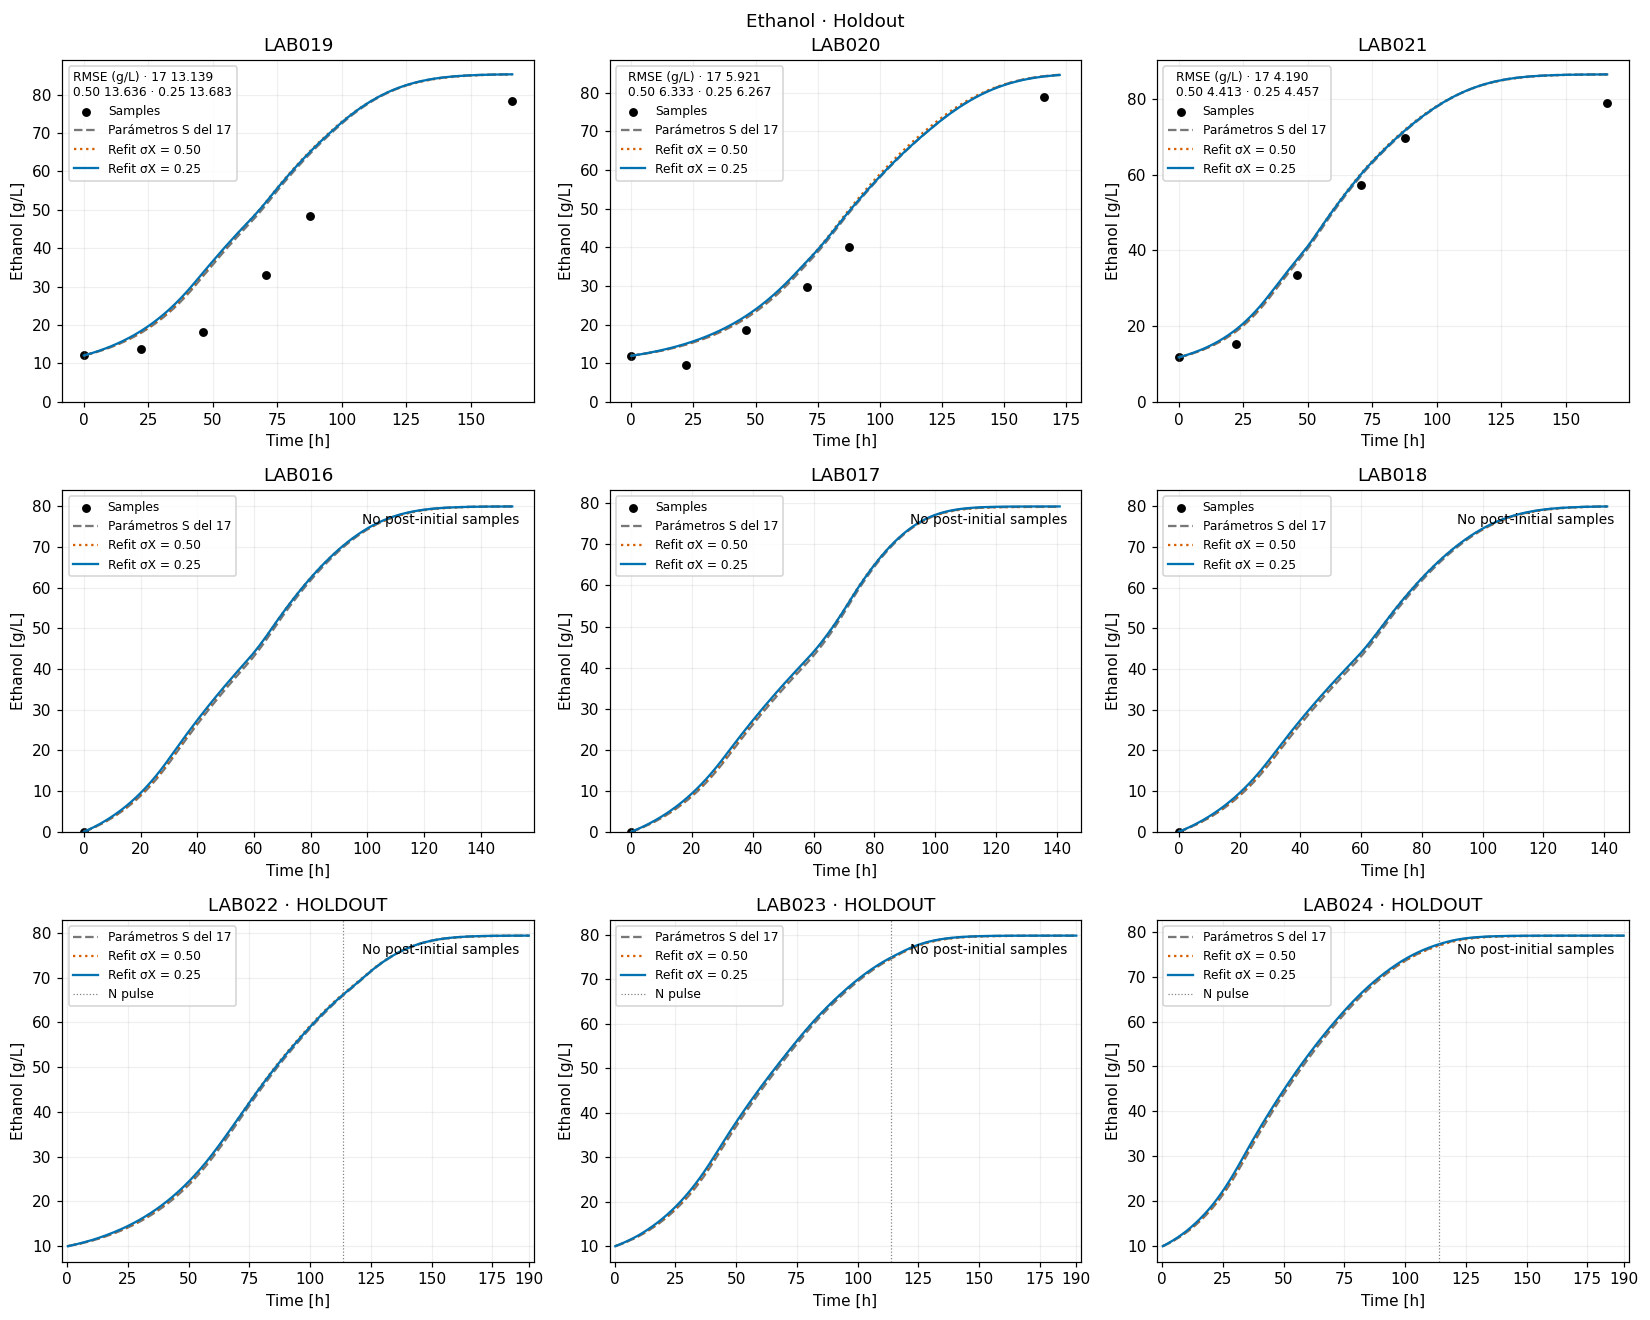

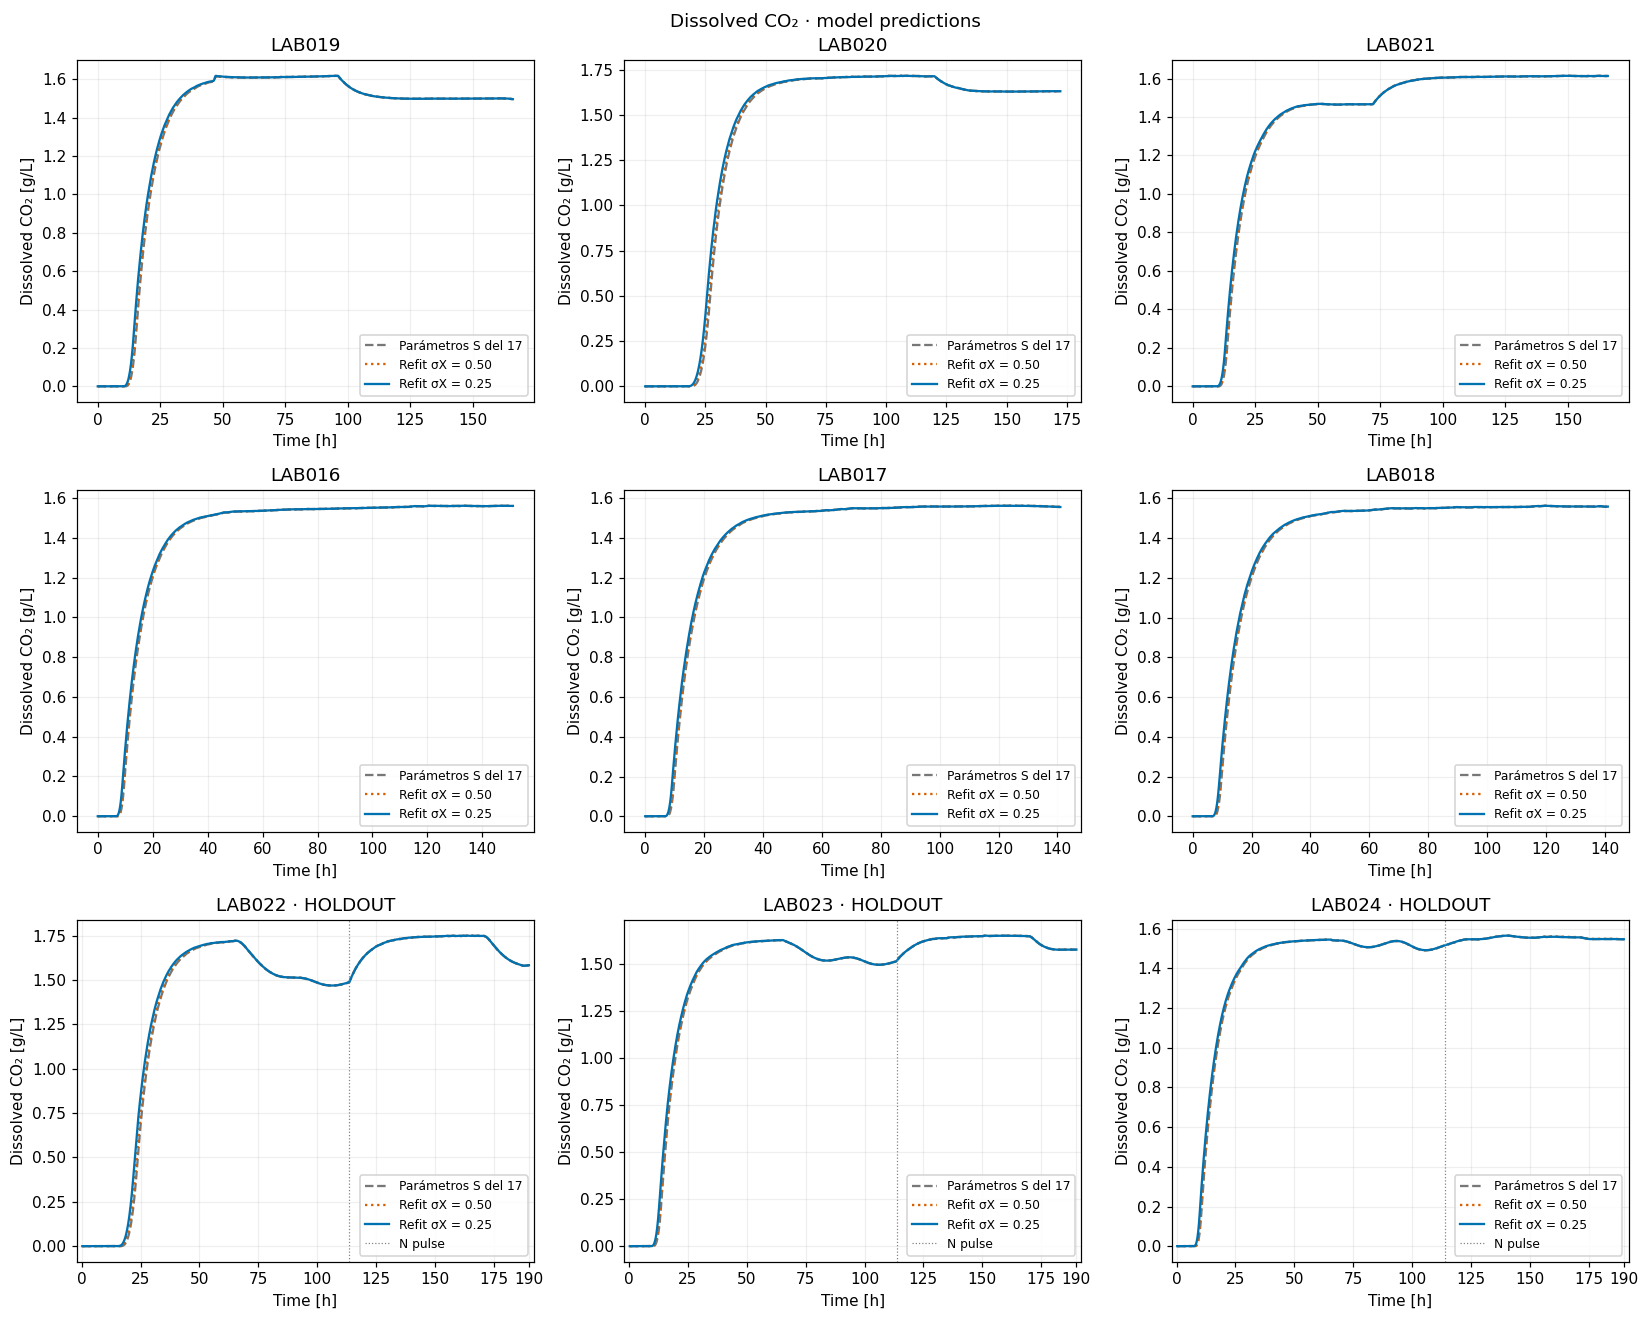

In [10]:
panels = {
    'X': ('Biomass','g/L',holdout_biomass,'X_g_L',1.),
    'N': ('YAN','mg/L',holdout_chemistry,'YAN for plot',1000.),
    'S': ('Total sugar','g/L',holdout_chemistry,'GLU-FRU-320',1.),
    'E': ('Ethanol','g/L',None,None,1.),
}
gas_unit = 'g/(L h)'


def draw_recent(ax,lab,state):
    group = 'LAB022–024'
    if state=='CO2':
        traces = chemical_frames(lab,holdout_mean_gas,reference_mean_gas)
        observed = holdout_flow[lab].dropna()
        observed = observed.loc[observed.index.intersection(traces[weighted_label].index)]
        ax.plot(observed.index,observed,color='black',lw=1,label='Samples')
        predictions = {label: trace.loc[observed.index].to_numpy() for label,trace in traces.items()}
        ax._rmse_text = score_comparison(group,lab,state,gas_unit,observed.index,observed.to_numpy(),predictions)
        title,unit = 'CO₂',gas_unit
    elif state=='Cd':
        frames = chemical_frames(lab,holdout_gas,reference_holdout_gas)
        traces = {label: frame.Cd for label,frame in frames.items()}
        title,unit = 'Dissolved CO₂','g/L'
    else:
        title,unit,sample_frame,column,scale = panels[state]
        frames = chemical_frames(lab,holdout_kinetic,reference_holdout)
        traces = {label: with_jumps(frame)[state]*scale for label,frame in frames.items()}
        if sample_frame is not None:
            samples = sample_frame.loc[sample_frame.lab.eq(lab)].dropna(subset=[column])
            ax.scatter(samples.hours,samples[column],c='black',s=23,label='Samples',zorder=5)
            evaluation = samples.loc[samples['sample'].ne('01')]
            times = evaluation.hours.to_numpy()
            predictions = {label: frame.loc[times,state].to_numpy()*scale for label,frame in frames.items()}
            ax._rmse_text = score_comparison(group,lab,state,unit,times,evaluation[column].to_numpy(),predictions)
        else:
            ax.text(.97,.9,'No post-initial samples',ha='right',transform=ax.transAxes,fontsize=9)
        if state=='S':
            density = prepared['offline']
            density = density.loc[density.lab.eq(lab)&density.hours.between(0,holdout_horizon)].dropna(subset=['Densidad_g_L'])
            ax.scatter(density.hours,2.5*(density.Densidad_g_L-1000),marker='D',facecolors='none',
                       edgecolors='#D55E00',s=32,label='G+F from density',zorder=4)
            ax.axhline(0,color='gray',lw=.6)
    plot_comparison(ax,traces,holdout_horizon)
    ax.axvline(holdout_nutrition[lab],c='gray',ls=':',lw=.8,label='N pulse')
    ax.set(title=f'{lab} · HOLDOUT',xlabel='Time [h]',ylabel=f'{title} [{unit}]',
           xlim=(-2,holdout_horizon+2),xticks=[0,25,50,75,100,125,150,175,190])
    ax.grid(alpha=.2)


def finish_panels(fig,axes,title,state):
    for ax,lab in zip(axes[-1],holdout_labs):
        draw_recent(ax,lab,state)
    for ax in axes.flat:
        lower,upper=ax.get_ylim()
        y_min,y_max=ax.dataLim.intervaly
        padding=.05*(y_max-y_min)
        if y_min<lower or y_max>upper:
            ax.set_ylim(min(lower,y_min-padding),max(upper,y_max+padding))
        lower,upper=ax.get_ylim()
        for line in ax.lines:
            if line.get_label() in parameters:
                values=np.asarray(line.get_ydata(),float)
                assert np.isfinite(values).all() and values.min()>=lower and values.max()<=upper
        legend_inside(ax)
    fig.suptitle(title,y=.99)
    fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9)
    plt.show()


fig,axes=plt.subplots(3,3,figsize=(15,12))
for ax,lab in zip(axes[:2].flat,LABS):
    frames=chemical_frames(lab,curves,reference_gas)
    traces={label: frame.qpred for label,frame in frames.items()}
    observed=obs[lab]
    times=observed.time_h.to_numpy()
    predictions={label: np.interp(times,trace.index,trace) for label,trace in traces.items()}
    group='LAB019–021' if lab in TRAIN else 'LAB016–018'
    ax._rmse_text=score_comparison(group,lab,'CO2',gas_unit,times,observed.co2_raw_g_l_h.to_numpy(),predictions)
    ax.plot(times,observed.co2_raw_g_l_h,c='black',lw=1,label='Samples')
    plot_comparison(ax,traces,v.horizons[lab])
    ax.set(title=lab+(' · gas calibration' if lab in TRAIN else ' · HOLDOUT'),
           xlabel='Time [h]',ylabel='CO₂ [g/(L·h)]',ylim=(0,None))
    ax.grid(alpha=.2)
finish_panels(fig,axes,'CO₂ · LAB016–024','CO2')

for state,(title,unit,_,_,scale) in panels.items():
    fig,axes=plt.subplots(3,3,figsize=(15,12))
    for ax,lab in zip(axes[:2].flat,LABS):
        frames=chemical_frames(lab,cores,reference_cores)
        traces={label: with_jumps(frame)[state]*scale for label,frame in frames.items()}
        times=np.array([])
        observed=np.array([])
        sample_label='Samples'
        if lab in TRAIN:
            assay='GF' if state=='S' else state
            rows=chemical_observations(v.chem,lab,assay)
            times=rows.t_h.to_numpy()
            observed=rows[CHEMICAL_COLUMNS[assay]].to_numpy()*scale
        elif state=='X':
            rows=v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h','X_viable_g_l'])
            times=rows.t_h.to_numpy()
            observed=rows.X_viable_g_l.to_numpy()
        elif state=='S':
            rows=v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l'])
            times=rows.t_h.to_numpy()
            observed=2.5*(rows.density_g_l.to_numpy()-1000)
            sample_label='G+F from density'
        score=(times>0)&(times<=v.horizons[lab])
        predictions={label: np.interp(times[score],trace.index,trace) for label,trace in traces.items()}
        group='LAB019–021' if lab in TRAIN else 'LAB016–018'
        ax._rmse_text=score_comparison(group,lab,state,unit,times[score],observed[score],predictions)
        if not score.any():
            ax.text(.97,.9,'No post-initial samples',ha='right',transform=ax.transAxes,fontsize=9)
        elif sample_label=='G+F from density':
            ax.scatter(times[score],observed[score],marker='D',facecolors='none',edgecolors='#D55E00',s=32,label=sample_label)
        else:
            ax.scatter(times[score],observed[score],c='black',s=23,label=sample_label,zorder=5)
        if state!='S' or lab in TRAIN:
            initial=batches[lab].initials
            value=initial['G']+initial['F'] if state=='S' else initial[state]
            ax.scatter([0.],[value*scale],c='black',s=23,label='Samples')
        if state=='S' and lab in TRAIN:
            density=v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l'])
            ax.scatter(density.t_h,2.5*(density.density_g_l-1000),marker='D',facecolors='none',
                       edgecolors='#D55E00',s=32,label='G+F from density')
        if state=='N':
            for time,dose in batches[lab].pulses['N']:
                ax.axvline(time,c='gray',ls=':',lw=.8,label='N pulse')
        if state=='S':
            ax.axhline(0,color='gray',lw=.6)
        plot_comparison(ax,traces,v.horizons[lab])
        if state!='S':
            ax.set_ylim(bottom=0)
        ax.set(title=lab,xlabel='Time [h]',ylabel=f'{title} [{unit}]')
        ax.grid(alpha=.2)
    finish_panels(fig,axes,title+' · Holdout',state)

fig,axes=plt.subplots(3,3,figsize=(15,12))
for ax,lab in zip(axes[:2].flat,LABS):
    frames=chemical_frames(lab,curves,reference_gas)
    plot_comparison(ax,{label: frame.Cd for label,frame in frames.items()},v.horizons[lab])
    ax.set(title=lab,xlabel='Time [h]',ylabel='Dissolved CO₂ [g/L]')
    ax.grid(alpha=.2)
finish_panels(fig,axes,'Dissolved CO₂ · model predictions','Cd')


## Comprobaciones y lectura final
La química fue reajustada con muestras depuradas tratadas, sin datos de validación. El gas usa solamente019–021 y una ganancia nueva. La conservación comprobada corresponde al depósito físico antes de ganancia. Una retirada homogénea conserva Cd y retira masa disuelta; la tabla de masas explicita ese término. Kn, límites y errores químicos deben revisarse junto al gas: una mejora del sensor no demuestra estados correctos ni parámetros únicos.


In [11]:
display(pd.DataFrame([dict(LAB=lab,t_h=j['t'],dosis_g_L=j['dose'],N_pre_g_L=j['before'][1],N_post_g_L=j['after'][1]) for lab,f in {**traincurves,**cores}.items() for j in f.attrs['pulse_jumps']]))
display(pd.DataFrame([dict(LAB=lab,**f.attrs['minimum_integrated_states']) for lab,f in cores.items()]))
masschecks=[]
for lab in LABS:
 f=curves[lab];t=f.index.to_numpy();V=volumes[lab](t);dt=np.diff(t);q=f.qprod.to_numpy();cd=f.Cd.to_numpy();out=f.qgas.to_numpy()
 produced=np.sum(V[:-1]*dt*q[1:]);emitted=np.sum(V[:-1]*dt*out[1:]);removed=np.sum((V[:-1]-V[1:])*cd[1:]);err=V[-1]*cd[-1]-V[0]*cd[0]-produced+emitted+removed
 assert abs(err)<1e-8
 masschecks.append(dict(LAB=lab,produccion_g=produced,gas_g=emitted,retirado_disuelto_g=removed,final_disuelto_g=V[-1]*cd[-1],error_g=err))
display(pd.DataFrame(masschecks))
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==h for p,h in hashes.items())
print('Archivos previos intactos; ninguna configuración ni dato sobrescrito.')
assert all(theta[k]==v for k,v in fixed.items())
print('Coeficientes de gas del modelo S del notebook 17:',KLA,GAIN)
print('RMSE medio gas por rol:',metrics.groupby('rol').RMSE.mean().to_dict())

# Evaluación independiente de términos_s, extraída del notebook 17.
reference_path=ROOT/'notebooks/17_zenteno_single_sugar_variable_solubility.source.ipynb'
reference_nb=nbformat.read(reference_path,4)
reference_code=next(cell.source for cell in reference_nb.cells if 'def terms_s(' in cell.source)
reference_terms=reference_code[reference_code.index('def terms_s'):reference_code.index('def simulate_s')]
ref_scope=dict(np=np,kin=kin,theta=theta)
exec(compile(reference_terms,str(reference_path),'exec'),ref_scope)
for state in (np.array([1.5,.07,125.,45.]),np.array([2.,.08,0.,95.])):
    for temperature in (16.,21.,30.):
        batch=replace(treated[0],temperature_c=np.full(len(treated[0].time),temperature))
        mu,beta,kd,maintenance=ref_scope['terms_s'](0.,state,theta,batch)
        expected=state[0]*np.array([mu-kd,-mu/theta['Yxn'],
                                    -(mu/theta['Yxs']+beta/theta['Yes']+maintenance),beta])
        np.testing.assert_allclose(chemical_rhs(state,parameter_vector(theta),temperature),expected,rtol=1e-12,atol=1e-12)

step_checks=[]
for batch in [*treated,*batches.values(),*holdout_batches.values()]:
    step_error=(simulate(batch,theta)-simulate(batch,theta,max_step=1/120)).abs().max()
    step_checks.append(dict(LAB=batch.batch,**step_error.to_dict()))
step_checks=pd.DataFrame(step_checks).set_index('LAB')
display(step_checks.round(5))
print('RK4_HALF_STEP_MAX_JSON',step_checks.max().to_json())


,LAB,t_h,dosis_g_L,N_pre_g_L,N_post_g_L
0,LAB004,68.500000,0.080000,1.420606e-21,0.080000
1,LAB005,68.500000,0.080000,7.369007e-23,0.080000
2,LAB006,100.000000,0.080000,9.326469e-16,0.080000
3,LAB007,65.500000,0.080000,1.208346e-18,0.080000
4,LAB008,65.500000,0.080000,3.976742e-16,0.080000
5,LAB009,41.846154,0.080000,7.189187e-10,0.080000
6,LAB019,64.333333,0.086486,4.761337e-17,0.086486
7,LAB020,71.666667,0.088889,6.832151e-06,0.088896
8,LAB021,47.500000,0.086486,2.194144e-11,0.086486
9,LAB016,56.935556,0.140000,4.179789e-22,0.140000


,LAB,X,N,S,E
0,LAB019,0.283162,5.437723e-105,0.029035,12.075372
1,LAB020,0.153342,3.178014e-88,0.469782,11.917524
2,LAB021,0.270000,4.100325e-120,0.009969,11.759676
3,LAB016,0.390000,3.205741e-95,0.043183,0.000000
4,LAB017,0.390000,1.699426e-116,0.000842,0.000000
5,LAB018,0.390000,6.146577e-95,0.044225,0.000000


,LAB,produccion_g,gas_g,retirado_disuelto_g,final_disuelto_g,error_g
0,LAB019,121.708475,118.791486,0.372340,2.544649,-1.310063e-14
1,LAB020,118.978488,115.866894,0.337890,2.773704,-1.665335e-15
2,LAB021,125.264184,122.161828,0.361725,2.740631,2.442491e-15
3,LAB016,146.125123,143.005000,0.000000,3.120123,0.000000e+00
4,LAB017,144.872778,141.772577,0.000000,3.100201,0.000000e+00
5,LAB018,146.138165,143.017468,0.000000,3.120697,-2.842171e-14


Archivos previos intactos; ninguna configuración ni dato sobrescrito.
Coeficientes de gas del modelo S del notebook 17: 0.13796553316180868 0.6586783889606775
RMSE medio gas por rol: {'Calibración gas': 0.131981931812085, 'Holdout gas': 0.1449701250630175}


,X,N,S,E
LAB,,,,
LAB004,0.00000,0.0,0.00000,0.00000
LAB005,0.00000,0.0,0.00000,0.00000
LAB006,0.00000,0.0,0.00000,0.00000
LAB007,0.00002,0.0,0.00009,0.00004
LAB008,0.00000,0.0,0.00000,0.00000
LAB009,0.00001,0.0,0.00001,0.00001
LAB019,0.00001,0.0,0.00004,0.00002
LAB020,0.00000,0.0,0.00000,0.00000
LAB021,0.00000,0.0,0.00000,0.00000


RK4_HALF_STEP_MAX_JSON {"X":0.0000206233,"N":0.0000004731,"S":0.0000868314,"E":0.0000393977}


## Efecto de la ponderación sobre la biomasa de holdout

El sesgo promedia la predicción menos la muestra. El exceso medio promedia la parte positiva de ese error y asigna cero a las subestimaciones. El promedio global da el mismo peso a cada lote.

RMSE                  ...    exceso_medio                
ajuste Parámetros S del 17 Refit σX = 0.50  ... Refit σX = 0.50 Refit σX = 0.25
LAB                                         ...                                
LAB016              0.3538          0.3527  ...          0.3411          0.2770
LAB017              0.5328          0.5314  ...          0.5205          0.4570
LAB018              0.3518          0.3522  ...          0.2995          0.2766
LAB019              0.4734          0.4719  ...          0.3356          0.2293
LAB020              0.5385          0.5359  ...          0.1222          0.0888
LAB021              0.5272          0.5260  ...          0.2309          0.1523
LAB022              0.4304          0.4290  ...          0.3218          0.2495
LAB023              0.5666          0.5641  ...          0.5006          0.3774
LAB024              0.8057          0.8030  ...          0.7398          0.6012

[9 rows x 9 columns]

,RMSE,MAE,sesgo,exceso_medio
ajuste,,,,
Parámetros S del 17,0.5089,0.4160,0.3448,0.3804
Refit σX = 0.50,0.5074,0.4149,0.3433,0.3791
Refit σX = 0.25,0.4375,0.3620,0.2401,0.3010


BIOMASS_HOLDOUT_JSON {"Par\u00e1metros S del 17":{"RMSE":0.5089073289,"MAE":0.4160169388,"sesgo":0.3447668551,"exceso_medio":0.3803918969},"Refit \u03c3X = 0.50":{"RMSE":0.5073612009,"MAE":0.4148712872,"sesgo":0.3433466834,"exceso_medio":0.3791089853},"Refit \u03c3X = 0.25":{"RMSE":0.4375028364,"MAE":0.3619528114,"sesgo":0.2400601544,"exceso_medio":0.3010064829}}


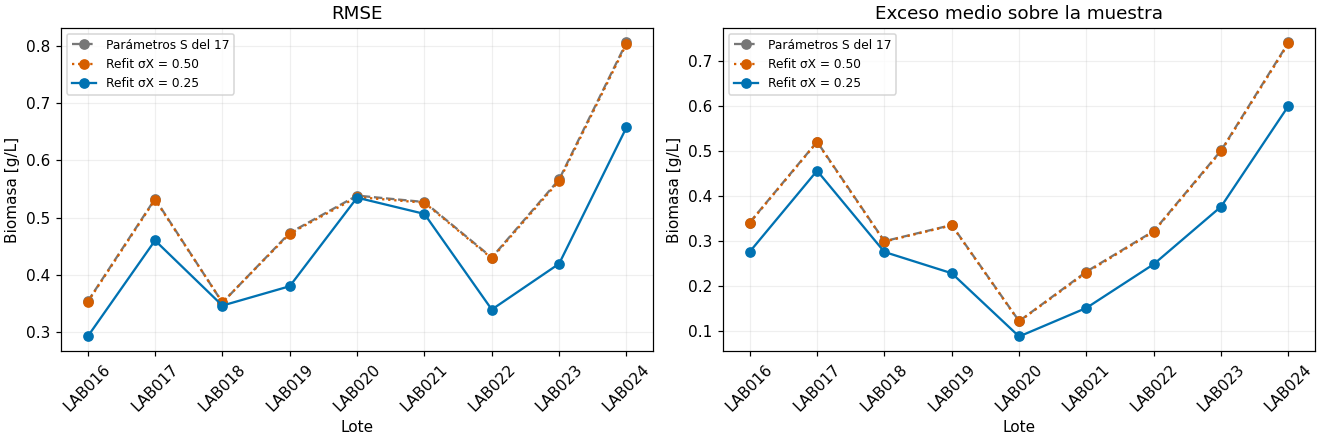

Muestras de biomasa en cada ajuste: 64.
σX de 0,25 menos σX de 0,50, promedio de los nueve lotes: ΔRMSE -0.0699 g/L; Δsesgo -0.1033 g/L; Δexceso medio -0.0781 g/L.
Lotes donde bajó el RMSE: 9/9. Lotes donde bajó el exceso medio: 9/9.


In [12]:
errors = pd.DataFrame(biomass_errors)
assert set(errors.LAB) == {*LABS, *holdout_labs}
assert errors.groupby(['LAB','t_h']).ajuste.nunique().eq(len(parameters)).all()
assert errors.groupby(['LAB','t_h']).observada.nunique().eq(1).all()
assert np.isfinite(errors[['observada','predicha','error']]).all().all()

scores = errors.assign(cuadrado=errors.error**2, absoluto=errors.error.abs(),
                       sobreestimacion=errors.error.clip(lower=0)).groupby(['LAB','ajuste']).agg(
    n=('error','size'), MSE=('cuadrado','mean'), MAE=('absoluto','mean'),
    sesgo=('error','mean'), exceso_medio=('sobreestimacion','mean'))
scores['RMSE'] = np.sqrt(scores.pop('MSE'))
columns = list(parameters)
comparison = scores[['RMSE','sesgo','exceso_medio']].unstack('ajuste')
display(comparison.reindex(columns=columns,level='ajuste').round(4))
means = scores.groupby('ajuste')[['RMSE','MAE','sesgo','exceso_medio']].mean().reindex(columns)
display(means.round(4))
print('BIOMASS_HOLDOUT_JSON', means.to_json(orient='index'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for ax, metric, title in zip(axes, ['RMSE','exceso_medio'], ['RMSE', 'Exceso medio sobre la muestra']):
 for label in columns:
  values = scores.xs(label,level='ajuste')[metric]
  ax.plot(values.index, values, marker='o', label=label,
          **styles[label])
 ax.set(title=title, ylabel='Biomasa [g/L]', xlabel='Lote')
 ax.tick_params(axis='x', labelrotation=45)
 ax.grid(alpha=.2)
 ax.legend(fontsize=8)
plt.show()

delta = means.loc[weighted_label] - means.loc[control_label]
rmse_by_lab = comparison['RMSE']
excess_by_lab = comparison['exceso_medio']
print(f'Muestras de biomasa en cada ajuste: {sum(row["X"] for row in rules)}.')
print(f'σX de 0,25 menos σX de 0,50, promedio de los nueve lotes: '
      f'ΔRMSE {delta.RMSE:+.4f} g/L; Δsesgo {delta.sesgo:+.4f} g/L; '
      f'Δexceso medio {delta.exceso_medio:+.4f} g/L.')
print(f'Lotes donde bajó el RMSE: {sum(rmse_by_lab[weighted_label] < rmse_by_lab[control_label])}/9. '
      f'Lotes donde bajó el exceso medio: {sum(excess_by_lab[weighted_label] < excess_by_lab[control_label])}/9.')


## Cambios en el ajuste de las demás variables

Cada RMSE usa las mismas observaciones para las tres trayectorias. Los promedios dan el mismo peso a cada lote con muestras. LAB016–018 aportan biomasa, azúcar total inferido por densidad y flujo de CO₂. En LAB022–024 se compara el azúcar total con el ensayo combinado GLU-FRU-320 y el etanol se muestra como predicción. El flujo usa medianas horarias en LAB016–021 y medias de 30 minutos en LAB022–024. El CO₂ disuelto se muestra como predicción.

In [13]:
paired=pd.DataFrame(paired_scores)
keys=['grupo','LAB','variable','unidad']
assert paired.groupby(keys).ajuste.nunique().eq(len(parameters)).all()
assert paired.groupby(keys).n.nunique().eq(1).all()
by_lab=paired.pivot(index=keys,columns='ajuste',values='RMSE').reindex(columns=list(parameters))
by_lab['Δ 0.25 − 0.50']=by_lab[weighted_label]-by_lab[control_label]
display(by_lab.round(4))
summary=by_lab.groupby(level=['grupo','variable','unidad']).mean()
display(summary.round(4))
print('PAIRED_RMSE_JSON',summary.reset_index().to_json(orient='records'))


ajuste                                       Parámetros S del 17  ...  Δ 0.25 − 0.50
grupo               LAB    variable unidad                        ...               
Calibración química LAB004 E        g/L                   4.6622  ...         0.0648
                           N        mg/L                 20.9810  ...         1.7359
                           S        g/L                   8.4731  ...         0.4515
                           X        g/L                   0.3465  ...        -0.1071
                    LAB005 E        g/L                   4.8008  ...         0.0727
                           N        mg/L                 23.5327  ...         1.4078
                           S        g/L                   6.2187  ...        -0.3887
                           X        g/L                   0.2360  ...        -0.1182
                    LAB006 E        g/L                   3.9951  ...         0.4230
                           N        mg/L                 33.8663  ...        -1.2317
                           S        g/L                  13.2468  ...         0.3774
                           X        g/L                   0.5072  ...         0.0341
                    LAB007 E        g/L                   2.4434  ...         0.0559
                           N        mg/L                 24.8641  ...         0.9854
                           S        g/L                   5.0330  ...         0.2266
                           X        g/L                   0.4356  ...        -0.1838
                    LAB008 E        g/L                   3.2015  ...        -0.1021
                           N        mg/L                 20.0744  ...         0.0875
                           S        g/L                   3.6167  ...         0.1054
                           X        g/L                   0.4043  ...        -0.1601
                    LAB009 E        g/L                   1.6493  ...         0.1050
                           N        mg/L                 34.5914  ...         1.6040
                           S        g/L                   5.1179  ...         0.2472
                           X        g/L                   0.5280  ...        -0.2014
LAB016–018          LAB016 CO2      g/(L h)               0.1415  ...         0.0050
                           S        g/L                   6.8817  ...        -0.1481
                           X        g/L                   0.3538  ...        -0.0601
                    LAB017 CO2      g/(L h)               0.1388  ...         0.0065
                           S        g/L                   3.7470  ...         0.0452
                           X        g/L                   0.5328  ...        -0.0713
                    LAB018 CO2      g/(L h)               0.1288  ...         0.0065
                           S        g/L                   4.2687  ...         0.0300
                           X        g/L                   0.3518  ...        -0.0057
LAB019–021          LAB019 CO2      g/(L h)               0.1233  ...         0.0010
                           E        g/L                  13.1389  ...         0.0472
                           N        mg/L                 42.2502  ...         2.3914
                           S        g/L                   7.7270  ...         0.4103
                           X        g/L                   0.4734  ...        -0.0916
                    LAB020 CO2      g/(L h)               0.0741  ...         0.0054
                           E        g/L                   5.9213  ...        -0.0653
                           N        mg/L                 10.8278  ...        -0.0880
                           S        g/L                   6.7080  ...        -0.2132
                           X        g/L                   0.5385  ...        -0.0010
                    LAB021 CO2      g/(L h)               0.1879  ...         0.0058
                           E        g/L                   4.1904  ...         0.0435
     

ajuste                                Parámetros S del 17  ...  Δ 0.25 − 0.50
grupo               variable unidad                        ...               
Calibración química E        g/L                   3.4587  ...         0.1032
                    N        mg/L                 26.3183  ...         0.7648
                    S        g/L                   6.9510  ...         0.1699
                    X        g/L                   0.4096  ...        -0.1227
LAB016–018          CO2      g/(L h)               0.1363  ...         0.0060
                    S        g/L                   4.9658  ...        -0.0243
                    X        g/L                   0.4128  ...        -0.0457
LAB019–021          CO2      g/(L h)               0.1284  ...         0.0041
                    E        g/L                   7.7502  ...         0.0085
                    N        mg/L                 22.4971  ...         1.1794
                    S        g/L                   9.3148  ...         0.0409
                    X        g/L                   0.5130  ...        -0.0374
LAB022–024          CO2      g/(L h)               0.1924  ...         0.0020
                    N        mg/L                 60.8659  ...         2.0920
                    S        g/L                  16.3685  ...         0.4772
                    X        g/L                   0.6009  ...        -0.1265

[16 rows x 4 columns]

PAIRED_RMSE_JSON [{"grupo":"Calibraci\u00f3n qu\u00edmica","variable":"E","unidad":"g\/L","Par\u00e1metros S del 17":3.4587194082,"Refit \u03c3X = 0.50":3.528737095,"Refit \u03c3X = 0.25":3.6319628418,"\u0394 0.25 \u2212 0.50":0.1032257468},{"grupo":"Calibraci\u00f3n qu\u00edmica","variable":"N","unidad":"mg\/L","Par\u00e1metros S del 17":26.3183254588,"Refit \u03c3X = 0.50":26.4428069703,"Refit \u03c3X = 0.25":27.2076345277,"\u0394 0.25 \u2212 0.50":0.7648275575},{"grupo":"Calibraci\u00f3n qu\u00edmica","variable":"S","unidad":"g\/L","Par\u00e1metros S del 17":6.9510359888,"Refit \u03c3X = 0.50":6.9941738462,"Refit \u03c3X = 0.25":7.164079561,"\u0394 0.25 \u2212 0.50":0.1699057148},{"grupo":"Calibraci\u00f3n qu\u00edmica","variable":"X","unidad":"g\/L","Par\u00e1metros S del 17":0.4095824685,"Refit \u03c3X = 0.50":0.4057570794,"Refit \u03c3X = 0.25":0.2830152463,"\u0394 0.25 \u2212 0.50":-0.1227418331},{"grupo":"LAB016\u2013018","variable":"CO2","unidad":"g\/(L h)","Par\u00e1metros S 

## Cambios de parámetros al dar más peso a la biomasa

La comparación usa los dos ajustes pareados y los parámetros del modelo S del notebook 17. Los parámetros libres se ordenan por cambio porcentual absoluto. Las cotas representan restricciones del optimizador.

In [14]:
parameter_audit=pd.DataFrame({
    'Notebook 17': pd.Series(published_theta),
    'σX = 0.50': pd.Series(parameters[control_label]),
    'σX = 0.25': pd.Series(parameters[weighted_label]),
})
parameter_audit['Δ %']=100*(parameter_audit['σX = 0.25']/parameter_audit['σX = 0.50']-1)
parameter_audit['Libre']=parameter_audit.index.isin(names)
parameter_audit['Mínimo']=pd.Series({k: v[0] for k,v in bounds.items()})
parameter_audit['Máximo']=pd.Series({k: v[1] for k,v in bounds.items()})
parameter_audit['Distancia al máximo (%)']=100*(1-parameter_audit['σX = 0.25']/parameter_audit['Máximo'])
ordered=parameter_audit.loc[names].sort_values('Δ %',key=abs,ascending=False)
assert parameter_audit.loc[~parameter_audit.Libre,'Δ %'].eq(0).all()
display(ordered.round(6))
display(parameter_audit.loc[~parameter_audit.Libre,['Notebook 17','σX = 0.50','σX = 0.25']].round(8))
print('PARAMETER_AUDIT_JSON',ordered.to_json(orient='index'))


,Notebook 17,σX = 0.50,σX = 0.25,Δ %,Libre,Mínimo,Máximo,Distancia al máximo (%)
Ks0,23.046565,26.399056,23.092504,-12.525267,True,0.10,200.0000,88.453748
Yxn,6.497332,6.476858,5.720952,-11.670866,True,1.00,100.0000,94.279048
betaS0,0.818966,0.858252,0.908349,5.837164,True,0.10,20.0000,95.458254
mu0,0.090851,0.091039,0.087293,-4.114519,True,0.05,1.0000,91.270718
Yes,0.489318,0.489394,0.486419,-0.607755,True,0.10,0.5114,4.884762


,Notebook 17,σX = 0.50,σX = 0.25
Kd0,0.000440,0.000440,0.000440
Kie0,96.265166,96.265166,96.265166
Kn0,0.008258,0.008258,0.008258
Yxs,0.516507,0.516507,0.516507
m0,0.018339,0.018339,0.018339


PARAMETER_AUDIT_JSON {"Ks0":{"Notebook 17":23.0465645671,"\u03c3X = 0.50":26.3990560259,"\u03c3X = 0.25":23.0925036783,"\u0394 %":-12.5252673595,"Libre":true,"M\u00ednimo":0.1,"M\u00e1ximo":200.0,"Distancia al m\u00e1ximo (%)":88.4537481609},"Yxn":{"Notebook 17":6.497331613,"\u03c3X = 0.50":6.4768576392,"\u03c3X = 0.25":5.7209522814,"\u0394 %":-11.6708657184,"Libre":true,"M\u00ednimo":1.0,"M\u00e1ximo":100.0,"Distancia al m\u00e1ximo (%)":94.2790477186},"betaS0":{"Notebook 17":0.8189664539,"\u03c3X = 0.50":0.8582516118,"\u03c3X = 0.25":0.9083491701,"\u0394 %":5.8371644947,"Libre":true,"M\u00ednimo":0.1,"M\u00e1ximo":20.0,"Distancia al m\u00e1ximo (%)":95.4582541493},"mu0":{"Notebook 17":0.0908505882,"\u03c3X = 0.50":0.0910386217,"\u03c3X = 0.25":0.0872928203,"\u0394 %":-4.1145190719,"Libre":true,"M\u00ednimo":0.05,"M\u00e1ximo":1.0,"Distancia al m\u00e1ximo (%)":91.2707179741},"Yes":{"Notebook 17":0.4893180893,"\u03c3X = 0.50":0.4893936378,"\u03c3X = 0.25":0.4864193258,"\u0394 %":-0.60